# 3.07 · Inference with surrogates: putting it together

*Topic 3 is under development: content and numbering may still change.*

**Before this:** [2.16](2-16_metropolis.ipynb) (Metropolis, detailed balance), [2.18](2-18_gradients_hmc_nuts.ipynb) (NUTS), [2.19](2-19_convergence_rhat.ipynb) (ESS, R-hat), [2.32](2-32_using_checking_posterior.ipynb) (simulation-based
calibration), 3.01-3.03 (surrogates, $\mathbf C_p$) · **You will be able to:** keep a cost ledger of true-model runs;
make a surrogate posterior honest by inflation; get the exact posterior with fewer runs by delayed acceptance; train
and check an amortised posterior network; choose a route for a given problem · **Optional sections:** 8 (ideas from
the literature).

Earlier notebooks built the pieces: surrogates (3.01-3.03), physics-informed and operator networks (3.04-3.05),
reduced models (3.06), ensembles that scale (2.26) and variational inference (2.21). This notebook puts a surrogate inside
a complete inference and asks the questions that decide whether it was worth it. What does the surrogate do to the
posterior, and how is the posterior kept honest? Can a surrogate save expensive runs without being trusted at all? What
does it cost to train a network that answers every future data set instantly, and how is such a network checked? It
ends with a decision table for common types of geophysical inverse problems. The currency throughout is **runs of
the true model**: every run a method needs, before the data and during sampling, counted and added up.

**Words this notebook defines:** cost ledger, true-model run, surrogate posterior, surrogate-error inflation,
delayed acceptance (two-stage Metropolis-Hastings), screening stage, subchain (two-level delayed acceptance),
effective samples per true-model run, amortised inference (neural posterior estimation), prior-predictive
simulations, mixture-density network, simulation-based calibration of an amortised posterior, sharpness,
misspecification, posterior predictive flag, derivative-informed surrogate, generative prior, decision table.

**Problems in this notebook** (size and forward model; notebook 2.25 explains the degree of nonlinearity)

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| single-patch afterslip, Δτ = 3 MPa known (as in 3.03) | 2: $\ln a\sigma$, $\ln v_0$ (uniform prior box) | 40 GPS epochs, day 1 to year 1, σ = 2 mm | exact closed-form solution of the friction ODE (derived in 3.04), checked here against the diffrax black box | no |
| the same, with a misspecified Earth (section 6) | 2 | the same epochs, plus an unmodelled offset or a wrong Δτ | the same | no |

Prior: uniform on the box $a\sigma$ 0.2-2 MPa, $v_0$ 0.001-1 m/yr (3.01, 3.03). We work in unit-box coordinates
$\mathbf u\in[0,1]^2$ as 3.03 does. Why two unknowns: with these data the three-parameter posterior is a thin filament
along a $v_0$-Δτ trade-off (3.03, section 1; 2.21, section 6), so Δτ is held at 3 MPa as if it came from the coseismic
model. The true model here is the closed form rather than the ODE solver, so that every exact answer can be computed;
the cell below checks that the two agree, and every run of it is **counted as if it were expensive**.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S

import time
T0 = time.time()
import inspect
import jax, jax.numpy as jnp
from scipy.stats import chisquare, binom
from matplotlib.lines import Line2D
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
from bayeskit import afterslip as A

SIG = 2.0                                               # GPS noise (mm)
DTAU = 3.0                                              # coseismic stress change, held known (MPa)
KST, GG = A.SP_DEFAULTS["k"], A.SP_DEFAULTS["g"]        # patch stiffness (MPa/m) and surface displacement per metre of slip
LO, HI = A.SP_BOUNDS[:2, 0], A.SP_BOUNDS[:2, 1]         # ln a_sigma, ln v0 box
TOBS = jnp.asarray(A.T_OBS)
C_TRUE, C_Q, C_C = S.INK, S.ORANGE, S.AQUA              # true model, quick surrogate, careful surrogate
C_NUTS = S.COLORS["nuts"]


def to_phys(U):
    """unit box -> (ln a_sigma, ln v0)"""
    return LO + (HI - LO) * np.asarray(U)


def u_closed(u01, dtau=DTAU):
    """Exact surface displacement (mm) of the single patch at unit-box inputs u01 (..., 2): sinh friction, not the log law.
    tau(t) = 2 a_s artanh(tanh(dtau / 2 a_s) exp(-2 k v0 t / a_s)) (3.04, section 1), u = g (dtau - tau) / k."""
    th = jnp.asarray(LO) + jnp.asarray(HI - LO) * u01
    a_s, v0 = jnp.exp(th[..., 0:1]), jnp.exp(th[..., 1:2])
    z = dtau / (2 * a_s)
    q = 2 * jnp.exp(-2 * z) / (1 + jnp.exp(-2 * z))                  # 1 - tanh(z) without cancellation
    c = 2 * KST * v0 / a_s
    e = jnp.exp(-c * TOBS)
    tau = a_s * jnp.log((1 + (1 - q) * e) / (-jnp.expm1(-c * TOBS) + q * e))
    return 1000.0 * GG * (dtau - tau) / KST


f_true = jax.jit(u_closed)
solver = jax.jit(jax.vmap(lambda u: 1000.0 * A.single_patch_series(
    jnp.stack([LO[0] + (HI[0] - LO[0]) * u[0], LO[1] + (HI[1] - LO[1]) * u[1], jnp.asarray(DTAU)]), A.T_OBS)))
U_chk = np.random.default_rng(0).uniform(size=(100, 2))
u_dfx, u_cf = np.asarray(solver(jnp.asarray(U_chk))), np.asarray(f_true(jnp.asarray(U_chk)))
print(f"closed form vs diffrax black box, 100 prior draws: largest difference {np.abs(u_dfx - u_cf).max():.1e} mm "
      f"(largest displacement {u_cf.max():.0f} mm; noise sigma {SIG} mm)")

# the cost of one run of the black box, for converting run counts into time (derived, not used in any inference)
one = jax.jit(lambda u: solver(u[None])[0])
lgrad = jax.jit(jax.value_and_grad(lambda u, d: -0.5 * jnp.sum((d - solver(u[None])[0]) ** 2) / SIG ** 2))
uu, dd = jnp.asarray(U_chk[0]), jnp.asarray(u_dfx[0])
one(uu).block_until_ready(); lgrad(uu, dd)[1].block_until_ready()
t0 = time.time()
for _ in range(20):
    one(uu).block_until_ready()
T_RUN = (time.time() - t0) / 20
t0 = time.time()
for _ in range(20):
    lgrad(uu, dd)[1].block_until_ready()
T_GRAD = (time.time() - t0) / 20
print(f"one diffrax run: {1e3 * T_RUN:.1f} ms; one run plus its gradient (reverse mode): {1e3 * T_GRAD:.1f} ms")

closed form vs diffrax black box, 100 prior draws: largest difference 3.6e-05 mm (largest displacement 600 mm; noise sigma 2.0 mm)


one diffrax run: 0.9 ms; one run plus its gradient (reverse mode): 4.7 ms


## 1. The cost ledger

**In plain words.** A surrogate does not make the expensive model go away; it moves the runs. Some routes spend them
before any data arrive (training), some during sampling, some on every new data set. To compare routes, add up all
runs of the true model that each one needs to deliver an answer of a stated quality. Training runs are forward runs:
the cost of an expensive simulator does not vanish when a surrogate is used, it moves to the training set.

**Precisely.** For a route $r$, with $c$ the cost of one true-model run (and $c_g$ that of a run plus its gradient),

$$\text{cost}_r = \underbrace{N_\text{train}\,c}_{\text{before the data}} + \underbrace{N_\text{infer}\,c \;(\text{or } c_g)}_{\text{per data set}},
\qquad \text{efficiency}_r = \frac{\text{effective samples of the exact posterior}}{N_\text{train} + N_\text{infer}}.$$

| route | $N_\text{train}$ | $N_\text{infer}$ per data set | answer |
|---|---|---|---|
| sampler on the true model (NUTS, 2.18; Metropolis, 2.16) | 0 | every step (NUTS: a run and a gradient per leapfrog step) | exact |
| sampler on a surrogate (3.01-3.03) | the design | 0 | the surrogate's posterior |
| delayed acceptance (section 4) | the design | one per proposal that passes the surrogate | exact |
| amortised network (section 5) | the simulations | 0 | the network's posterior, for any data set |

$N_\text{train}$ means *every* run spent before the first data set, not only the runs the surrogate is fitted to. In
this notebook that is three kinds: **pilot** runs (400) that fix the output compression, **validation** runs (400)
that check the compression and estimate the surrogate error $\mathbf C_p$, and the **training** runs of each surrogate.
Pilot and validation runs are shared by both surrogates and by the amortised network, so they are counted once when
the methods are built together, and once for each method when it is built alone (its *first-use* cost). When one
pipeline then serves many data sets, its first-use cost is spread over all of them (*amortisation*); the cost per
data set during sampling is reported separately. Runs made only to grade the methods (the exact reference posteriors,
the repeated synthetic data sets) are not charged to any method.

The rest of the notebook fills in the ledger with measured counts. The black box takes milliseconds here (timings
printed above), so counts, not seconds, are the fair currency; the cell above gives the conversion, including what a
run with its gradient costs in forward runs.

## 2. NUTS on a surrogate vs NUTS on the true model

**In plain words.** Fit a surrogate to a few hundred runs, then let NUTS sample the posterior with the surrogate in
place of the model. Every NUTS step is now nearly free; the price was paid in the training runs. The question is
whether the answer is the same posterior.

**Precisely.** We reuse the recipe of 3.01 and 3.02: a Latin-hypercube design over the prior box, the 40-epoch outputs
compressed to $K$ principal components (3.01's rule: the smallest $K$ whose worst reconstruction error on validation
runs is below 0.05 σ), and a deep ensemble of five tanh networks (2 → 64 → 64 → K, 3.02) trained by Adam on the
coefficients. Two surrogates, which differ in both knobs, as they often do in practice:
* **quick**: 100 runs, 3,000 Adam steps;
* **careful**: 400 runs, 12,000 Adam steps.

The surrogate's prediction is the ensemble mean. NumPyro NUTS (4 chains, 500 warm-up and 1,000 draws each) then
samples three posteriors of the same data set (the 3.03 parameters, $a\sigma$ = 0.6 MPa, $v_0$ = 0.03 m/yr): with the
true model, with the quick and with the careful surrogate. The yardstick is the exact posterior of the true model on a
grid (as in 3.01, section 7).

In [2]:
def lhs(rng, n, d=2):
    """Latin hypercube in the unit box (3.01): each axis cut into n strata, one point per stratum."""
    return (np.argsort(rng.uniform(size=(n, d)), axis=0) + rng.uniform(size=(n, d))) / n


RUNS = {"n": 0}


def run_true(U):
    """The expensive model at unit-box inputs U (m, 2); every row counts as one run."""
    U = np.atleast_2d(U)
    RUNS["n"] += len(U)
    return np.asarray(f_true(jnp.asarray(U)))


U_val = lhs(np.random.default_rng(99), 400)               # validation runs: used for K and for C_p, never for training
Y_val = run_true(U_val)
U_big = lhs(np.random.default_rng(410), 400)
Y_big = run_true(U_big)
MU_b = Y_big.mean(0)
VT_b = np.linalg.svd(Y_big - MU_b, full_matrices=False)[2]
worst = [np.abs((Y_val - MU_b) @ VT_b[:k].T @ VT_b[:k] + MU_b - Y_val).max() for k in range(1, 16)]
ok_k = np.array(worst) < 0.05 * SIG
if not ok_k.any():                                       # argmax of an all-False array would silently give K = 1
    raise RuntimeError("no K up to 15 reaches the 0.05 sigma rule; raise the largest K tried")
K = 1 + int(np.argmax(ok_k))
SHARED = {"pilot runs (choose the compression)": len(U_big), "validation runs (check K, estimate C_p)": len(U_val)}
print("worst validation reconstruction error (mm) for K = 1..15:", np.array2string(np.array(worst), precision=3))
print(f"3.01's rule (worst error < 0.05 sigma = {0.05 * SIG} mm) gives K = {K}")


def init_mlp(key, sizes, scale=1.0):
    """Weights ~ N(0, scale^2 / n_in), biases 0 (3.02)."""
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        key, k = jax.random.split(key)
        params.append((scale * jax.random.normal(k, (n_in, n_out)) / np.sqrt(n_in), jnp.zeros(n_out)))
    return params


def mlp(params, x, act=jnp.tanh):
    for W, b in params[:-1]:
        x = act(x @ W + b)
    W, b = params[-1]
    return x @ W + b


def adam(loss, params, n_steps, lr=3e-3, b1=0.9, b2=0.999, eps=1e-8):
    """Adam with a cosine-decaying step (3.02, section 6), full batch."""
    def step(carry, i):
        p, m, v = carry
        L, g = jax.value_and_grad(loss)(p)
        t = i + 1.0
        lr_t = lr * 0.5 * (1 + jnp.cos(jnp.pi * i / n_steps))
        m = jax.tree.map(lambda m_, g_: b1 * m_ + (1 - b1) * g_, m, g)
        v = jax.tree.map(lambda v_, g_: b2 * v_ + (1 - b2) * g_ ** 2, v, g)
        p = jax.tree.map(lambda p_, m_, v_: p_ - lr_t * (m_ / (1 - b1 ** t)) / (jnp.sqrt(v_ / (1 - b2 ** t)) + eps),
                         p, m, v)
        return (p, m, v), L
    zeros = jax.tree.map(jnp.zeros_like, params)
    (params, _, _), hist = jax.lax.scan(step, (params, zeros, zeros), jnp.arange(n_steps, dtype=jnp.float64))
    return params, hist


def train_surrogate(n, steps, seed, members=5):
    """Design of n runs -> PCA (K) -> ensemble of MLPs. Returns pred(U) = (ensemble mean, ensemble variance) in mm."""
    U_ = lhs(np.random.default_rng(10 + n), n)
    Y_ = run_true(U_)
    mu = Y_.mean(0)
    VT = np.linalg.svd(Y_ - mu, full_matrices=False)[2][:K]
    Z = (Y_ - mu) @ VT.T
    zs = Z.std()                                                # one output scale for all coefficients (3.02)
    X, Zn = jnp.asarray(2 * U_ - 1), jnp.asarray(Z / zs)
    train_one = lambda key: adam(lambda p: jnp.mean((mlp(p, X) - Zn) ** 2), init_mlp(key, [2, 64, 64, K]), steps)[0]
    ens = jax.jit(jax.vmap(train_one))(jax.random.split(jax.random.PRNGKey(seed), members))
    VTj, muj = jnp.asarray(VT), jnp.asarray(mu)

    @jax.jit
    def pred(U):
        Pm = jax.vmap(lambda p: (mlp(p, 2 * U - 1) * zs) @ VTj + muj)(ens)
        return Pm.mean(0), Pm.var(0, ddof=1)
    return pred, ens, (mu, VT, zs)


t0 = time.time()
n0 = RUNS["n"]
SUR = {}
for name, n, steps in (("quick", 100, 3000), ("careful", 400, 12000)):
    SUR[name] = dict(n=n, steps=steps)
    SUR[name]["pred"], SUR[name]["ens"], SUR[name]["basis"] = train_surrogate(n, steps, seed=n)
    m_val, v_val = (np.asarray(a) for a in SUR[name]["pred"](jnp.asarray(U_val)))
    r_val = Y_val - m_val
    SUR[name]["Cp"] = r_val.T @ r_val / len(U_val)              # global C_p from validation residuals (3.01, section 7)
    e_val = np.sqrt((r_val ** 2).mean(1))
    print(f"{name:8s}: {n} training runs, {steps} Adam steps; validation RMS error {np.sqrt((r_val ** 2).mean()):.2f} mm "
          f"(median over runs {np.median(e_val):.2f}, worst {e_val.max():.2f} mm; noise sigma {SIG} mm)")
print(f"training both ensembles: {time.time() - t0:.0f} s; true-model runs used for training: {RUNS['n'] - n0}")
N_SHARED = sum(SHARED.values())
FIRST = {name: N_SHARED + SUR[name]["n"] for name in SUR}          # every run a pipeline needs before its first data set
print("ledger before any data (forward runs, no gradients): " + "; ".join(f"{k} {v}" for k, v in SHARED.items()))
for name in SUR:
    print(f"  {name} surrogate, first use: {N_SHARED} shared + {SUR[name]['n']} training = {FIRST[name]} runs")
print(f"  both surrogates built together: {N_SHARED + sum(SUR[n_]['n'] for n_ in SUR)} runs (the shared runs counted once);"
      f" true-model runs counted so far {RUNS['n']}")

worst validation reconstruction error (mm) for K = 1..15: [1.941e+02 7.489e+01 3.417e+01 9.256e+00 3.020e+00 1.312e+00 3.878e-01
 2.705e-01 1.230e-01 3.682e-02 1.769e-02 8.961e-03 4.439e-03 1.736e-03
 7.772e-04]
3.01's rule (worst error < 0.05 sigma = 0.1 mm) gives K = 10


quick   : 100 training runs, 3000 Adam steps; validation RMS error 1.68 mm (median over runs 0.88, worst 10.81 mm; noise sigma 2.0 mm)


careful : 400 training runs, 12000 Adam steps; validation RMS error 0.27 mm (median over runs 0.16, worst 2.13 mm; noise sigma 2.0 mm)
training both ensembles: 15 s; true-model runs used for training: 500
ledger before any data (forward runs, no gradients): pilot runs (choose the compression) 400; validation runs (check K, estimate C_p) 400
  quick surrogate, first use: 800 shared + 100 training = 900 runs
  careful surrogate, first use: 800 shared + 400 training = 1200 runs
  both surrogates built together: 1300 runs (the shared runs counted once); true-model runs counted so far 1300


In [3]:
U0 = np.array([np.log(0.6 / 0.2) / np.log(10), np.log(0.03 / 0.001) / np.log(1000)])   # a_sigma 0.6 MPa, v0 0.03 m/yr
d0 = np.asarray(f_true(jnp.asarray(U0[None])))[0] + SIG * np.random.default_rng(1).standard_normal(40)
inside = lambda G: jnp.all((G >= 0) & (G <= 1), 1)


@jax.jit
def ll_true(G, d):
    """ln p(d | u) of the true model on a batch of unit-box points (uniform prior: -inf outside the box)."""
    r = d[None] - f_true(jnp.clip(G, 0, 1))
    return jnp.where(inside(G), -0.5 * jnp.sum(r ** 2, 1) / SIG ** 2, -jnp.inf)


def ll_surrogate(pred, mode="none", Cp=None):
    """ln p(d | u) with a surrogate: mode 'none' (C_d only), 'Cp' (C_d + global C_p) or 'ens' (C_d + ensemble variance)."""
    Ci = None if Cp is None else jnp.asarray(np.linalg.inv(SIG ** 2 * np.eye(40) + Cp))

    @jax.jit
    def ll(G, d):
        mu, var = pred(jnp.clip(G, 0, 1))
        r = d[None] - mu
        if mode == "none":
            out = -0.5 * jnp.sum(r ** 2, 1) / SIG ** 2
        elif mode == "Cp":
            out = -0.5 * jnp.sum((r @ Ci) * r, 1)
        else:                                                   # the 1 + s^2 term of 3.03, per epoch
            v = SIG ** 2 + var
            out = -0.5 * jnp.sum(r ** 2 / v + jnp.log(v), 1)
        return jnp.where(inside(G), out, -jnp.inf)
    return ll


def rotated_grid(m, Cw, ng, W=7.0):
    """ng x ng grid over +-W standard deviations along the principal axes of Cw around m (3.01, section 7)."""
    lam, R = np.linalg.eigh(Cw)
    B = R * np.sqrt(np.maximum(lam, 1e-30))
    g = np.linspace(-W, W, ng)
    step = B * (g[1] - g[0])
    return m + np.stack(np.meshgrid(g, g, indexing="ij"), -1).reshape(-1, 2) @ B.T, step @ step.T


def grid_moments(G, p, step_cov):
    m = p @ G
    return m, ((G - m) * p[:, None]).T @ (G - m) + step_cov


def make_posterior(ll, nlev=3, ng=90):
    """Exact posterior of ll on grids: the whole box, then two grids along the posterior's principal axes (3.01)."""
    g = np.linspace(0, 1, ng)
    G0, h = np.stack(np.meshgrid(g, g, indexing="ij"), -1).reshape(-1, 2), g[1] - g[0]

    def post(d, u_true=None):
        G, step_cov, dj = G0, np.diag([h * h, h * h]), jnp.asarray(d)
        for lev in range(nlev):
            if lev > 0:
                G, step_cov = rotated_grid(*grid_moments(G, p, step_cov), ng)
            lp = np.asarray(ll(jnp.asarray(G), dj))
            p = np.exp(lp - lp.max())
            p /= p.sum()
        P2 = p.reshape(ng, ng)
        out = dict(G=G, p=p, P2=P2, edge=P2[0].sum() + P2[-1].sum() + P2[:, 0].sum() + P2[:, -1].sum())
        out["m"], out["C"] = grid_moments(G, p, step_cov)
        if u_true is not None:                                 # posterior mass denser than the true value (coverage)
            out["frac"] = p[lp > float(ll(jnp.asarray(u_true[None]), dj)[0])].sum()
        return out
    return post


post_true = make_posterior(ll_true)
EX = post_true(d0, U0)
sd_ex = np.sqrt(np.diag(EX["C"]))
print(f"exact posterior (true model, grid): mean u = {np.round(EX['m'], 4)}, sd = {np.round(sd_ex, 5)} "
      f"(unit box); in physical units sd of ln a_sigma {sd_ex[0] * (HI[0] - LO[0]):.4f}, of ln v0 {sd_ex[1] * (HI[1] - LO[1]):.4f}")


def inside90(post, X):
    """Is each point X inside the 90 % region of a gridded posterior? (density above the 90 % level, interpolated
    from the nearest grid node in the posterior's own whitened coordinates)."""
    ps = np.sort(post["p"])[::-1]
    lev = ps[np.searchsorted(np.cumsum(ps), 0.9)]
    Lc = np.linalg.cholesky(post["C"])
    W = np.linalg.solve(Lc, (post["G"] - post["m"]).T).T
    Wx = np.linalg.solve(Lc, (np.atleast_2d(X) - post["m"]).T).T
    from scipy.spatial import cKDTree
    _, idx = cKDTree(W).query(Wx)
    dist_ok = np.abs(Wx).max(1) < np.abs(W).max()
    return (post["p"][idx] >= lev) & dist_ok


def nuts_run(fwd, seed=0, nw=500, ns=1000, chains=4):
    """NumPyro NUTS on the unit box; returns draws (chains, ns, 2), leapfrog steps (warm-up, sampling) and wall time."""
    def model():
        u = numpyro.sample("u", dist.Uniform(jnp.zeros(2), jnp.ones(2)).to_event(1))
        numpyro.sample("obs", dist.Normal(fwd(u[None])[0], SIG), obs=jnp.asarray(d0))
    mc = MCMC(NUTS(model), num_warmup=nw, num_samples=ns, num_chains=chains, progress_bar=False,
              chain_method="sequential")
    t0 = time.time()
    mc.warmup(jax.random.PRNGKey(seed), extra_fields=("num_steps",), collect_warmup=True)
    n_w = int(np.sum(mc.get_extra_fields()["num_steps"]))
    mc.run(jax.random.PRNGKey(seed + 1), extra_fields=("num_steps",))
    n_s = int(np.sum(mc.get_extra_fields()["num_steps"]))
    return np.asarray(mc.get_samples(group_by_chain=True)["u"]), (n_w, n_s), time.time() - t0


def grade(draws):
    """Against the exact grid posterior: mean shift and sd ratio per parameter, share of draws inside its 90 % region."""
    flat = draws.reshape(-1, 2)
    return dict(shift=(flat.mean(0) - EX["m"]) / sd_ex, sdr=flat.std(0) / sd_ex, in90=inside90(EX, flat).mean(),
                rhat=max(D.rhat(draws[..., i]) for i in range(2)), ess=min(D.ess(draws[..., i]) for i in range(2)))


NUTS_RES = {}
for name, fwd in (("true model", f_true), ("quick surrogate", lambda u: SUR["quick"]["pred"](u)[0]),
                  ("careful surrogate", lambda u: SUR["careful"]["pred"](u)[0])):
    draws, (n_w, n_s), tt = nuts_run(fwd)
    g = grade(draws)
    NUTS_RES[name] = dict(draws=draws, steps=(n_w, n_s), time=tt, **g)
    print(f"NUTS, {name:17s}: {tt:5.1f} s; leapfrog steps warm-up {n_w}, sampling {n_s}; R-hat {g['rhat']:.3f}, "
          f"ESS {g['ess']:.0f}; mean shift {np.round(g['shift'], 2)} exact sd, sd ratio {np.round(g['sdr'], 2)}; "
          f"share of draws inside the exact 90 % region {g['in90']:.2f}")
steps_true = sum(NUTS_RES["true model"]["steps"])
print(f"\nledger, true-model runs for one posterior: NUTS on the true model {steps_true:,} runs, each with its gradient "
      f"(warm-up included); quick surrogate {FIRST['quick']:,}, careful surrogate {FIRST['careful']:,} forward runs before "
      f"the data, none during sampling")
print(f"here one run with its gradient costs {T_GRAD / T_RUN:.1f} forward runs (timings above)")
print(f"if each NUTS step were a diffrax run with its gradient: {steps_true * T_GRAD:.0f} s (derived from the timing above)")

exact posterior (true model, grid): mean u = [0.4783 0.4938], sd = [0.00313 0.00392] (unit box); in physical units sd of ln a_sigma 0.0072, of ln v0 0.0271


NUTS, true model       :   4.2 s; leapfrog steps warm-up 28988, sampling 52712; R-hat 1.009, ESS 686; mean shift [0.   0.01] exact sd, sd ratio [0.96 0.97]; share of draws inside the exact 90 % region 0.90


NUTS, quick surrogate  :   3.4 s; leapfrog steps warm-up 29181, sampling 55786; R-hat 1.004, ESS 700; mean shift [-0.78 -0.77] exact sd, sd ratio [0.98 0.99]; share of draws inside the exact 90 % region 0.82


NUTS, careful surrogate:   3.7 s; leapfrog steps warm-up 28795, sampling 57970; R-hat 1.005, ESS 751; mean shift [0.08 0.07] exact sd, sd ratio [0.96 0.96]; share of draws inside the exact 90 % region 0.90

ledger, true-model runs for one posterior: NUTS on the true model 81,700 runs, each with its gradient (warm-up included); quick surrogate 900, careful surrogate 1,200 forward runs before the data, none during sampling
here one run with its gradient costs 5.1 forward runs (timings above)
if each NUTS step were a diffrax run with its gradient: 382 s (derived from the timing above)


long axis of the exact posterior in (ln a_sigma, ln v0): direction [0.256 0.967]; sd along it 0.0050, across it 0.00048 (unit box)


saved figures/3-07_nuts_on_surrogate.png


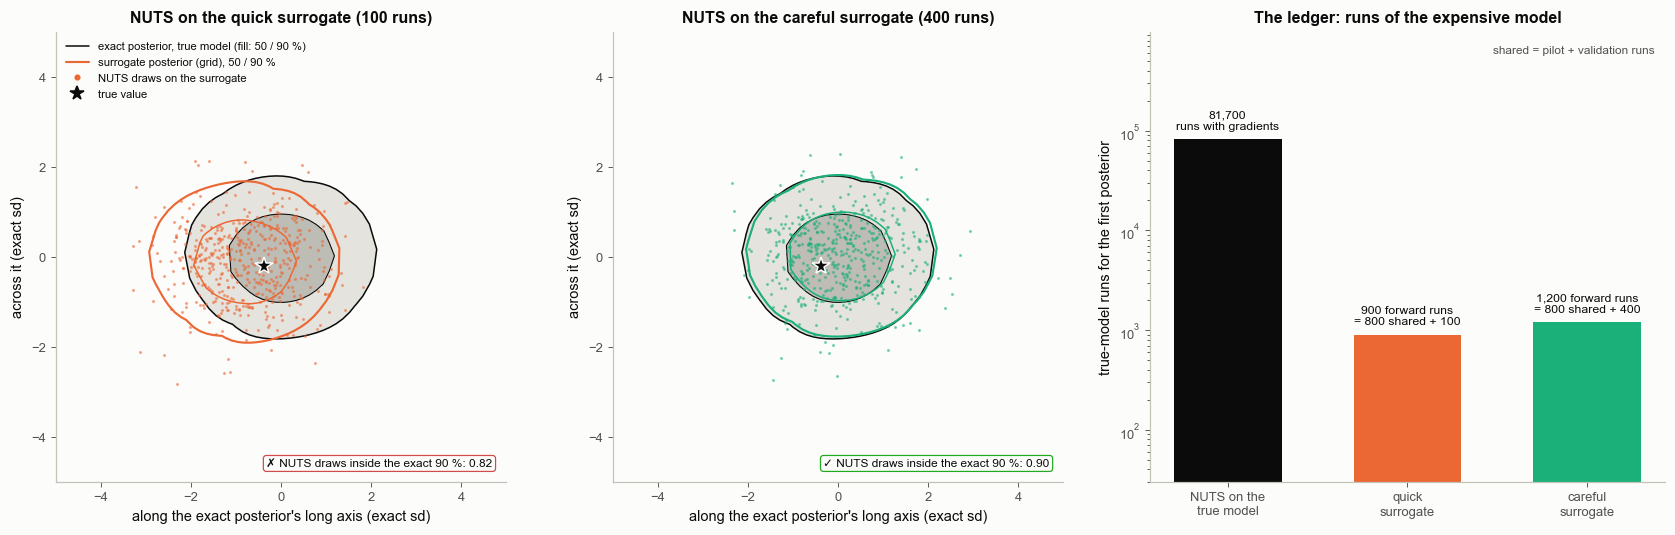

In [4]:
lam_ex, R_ex = np.linalg.eigh(EX["C"])
R_ex, lam_ex = R_ex[:, ::-1], lam_ex[::-1]                     # long axis first
R_ex = R_ex * np.sign(R_ex[0])                                 # both axes point towards larger ln a_sigma


def whiten(U):
    """Coordinates along the exact posterior's principal axes, in its standard deviations (the exact posterior becomes
    a round blob, so shifts and widths are visible; in (ln a_sigma, ln v0) it is a thin diagonal sliver)."""
    return (np.atleast_2d(U) - EX["m"]) @ R_ex / np.sqrt(lam_ex)


long_dir = R_ex[:, 0] * (HI - LO)
print(f"long axis of the exact posterior in (ln a_sigma, ln v0): direction {np.round(long_dir / np.linalg.norm(long_dir), 3)}; "
      f"sd along it {np.sqrt(lam_ex[0]):.4f}, across it {np.sqrt(lam_ex[1]):.5f} (unit box)")


def hdr_contour(ax, post, col, lw=1.6, fill=False, levels=(0.9, 0.5), zorder=2):
    """50 % and 90 % regions of a gridded posterior (curvilinear grid), drawn in the whitened coordinates."""
    P2 = post["P2"]
    ps = np.sort(P2.ravel())[::-1]
    cs = np.cumsum(ps)
    levs = [ps[np.searchsorted(cs, q_)] for q_ in levels]
    ng = P2.shape[0]
    X = whiten(post["G"])
    X0, X1 = X[:, 0].reshape(ng, ng), X[:, 1].reshape(ng, ng)
    if fill:
        ax.contourf(X0, X1, P2, levels=[levs[0], levs[1], P2.max() * 1.01], colors=["#e4e3dd", "#bdbcb5"], zorder=zorder)
    ax.contour(X0, X1, P2, levels=levs, colors=[col, col], linewidths=[lw, lw * 0.7], zorder=zorder + 0.1)


post_q = make_posterior(ll_surrogate(SUR["quick"]["pred"]))(d0)
post_c = make_posterior(ll_surrogate(SUR["careful"]["pred"]))(d0)
fig, axs = plt.subplots(1, 3, figsize=(15.5, 4.9), gridspec_kw=dict(width_ratios=[1, 1, 1.05]))
for ax, name, col, pst in ((axs[0], "quick surrogate", C_Q, post_q), (axs[1], "careful surrogate", C_C, post_c)):
    hdr_contour(ax, EX, C_TRUE, lw=1.0, fill=True)
    hdr_contour(ax, pst, col, lw=1.4, zorder=3)
    X = whiten(NUTS_RES[name]["draws"].reshape(-1, 2)[::8])
    ax.plot(X[:, 0], X[:, 1], ".", color=col, ms=2.2, alpha=0.45, zorder=4)
    ax.plot(*whiten(U0)[0], "*", color=S.INK, ms=12, mec=S.SURFACE, zorder=6)
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5); ax.set_aspect("equal")
    ax.set_xlabel("along the exact posterior's long axis (exact sd)"); ax.set_ylabel("across it (exact sd)")
    g = NUTS_RES[name]
    ok = abs(g["in90"] - 0.9) < 0.05
    S.badge(ax, f"NUTS draws inside the exact 90 %: {g['in90']:.2f}", ok=ok, loc="lower right", fs=7.8)
    ax.set_title(f"NUTS on the {name} ({SUR[name.split()[0]]['n']} runs)")
axs[0].legend(handles=[Line2D([], [], color=C_TRUE, lw=1.0, label="exact posterior, true model (fill: 50 / 90 %)"),
                       Line2D([], [], color=C_Q, lw=1.4, label="surrogate posterior (grid), 50 / 90 %"),
                       Line2D([], [], color=C_Q, marker=".", ls="", label="NUTS draws on the surrogate"),
                       Line2D([], [], color=S.INK, marker="*", ls="", ms=9, label="true value")],
              fontsize=7.4, loc="upper left")
ax = axs[2]
labs = ["NUTS on the\ntrue model", "quick\nsurrogate", "careful\nsurrogate"]
vals = [steps_true, FIRST["quick"], FIRST["careful"]]
cols = [C_TRUE, C_Q, C_C]
ax.bar(labs, vals, color=cols, width=0.6)
notes = [f"{steps_true:,}\nruns with gradients", f"{FIRST['quick']:,} forward runs\n= {N_SHARED} shared + {SUR['quick']['n']}",
         f"{FIRST['careful']:,} forward runs\n= {N_SHARED} shared + {SUR['careful']['n']}"]
for i, (v, t_) in enumerate(zip(vals, notes)):
    ax.text(i, v * 1.25, t_, ha="center", fontsize=8)
ax.set_yscale("log"); ax.set_ylim(30, steps_true * 12)
ax.set_ylabel("true-model runs for the first posterior")
ax.text(0.98, 0.97, "shared = pilot + validation runs", transform=ax.transAxes, fontsize=7.8, color=S.INK2,
        ha="right", va="top")
ax.set_title("The ledger: runs of the expensive model")
fig.tight_layout()
bk.savefig(fig, "3-07_nuts_on_surrogate")
plt.show()

**How to read it.** The two left panels use the exact posterior's principal axes as coordinates, in units of its
standard deviations (the long axis is printed above: mostly the $\ln a\sigma$-$\ln v_0$ trade-off). In these
coordinates the exact posterior is a round blob; in $(\ln a\sigma, \ln v_0)$ it is a sliver too thin to show a shift.
Left and middle: the grey regions are the exact posterior of the expensive model; the coloured
lines are the surrogate's own posterior (computed on a grid) and the dots are NUTS draws from it. NUTS samples the
surrogate's posterior faithfully in both cases (the dots fill the coloured lines; R-hat and ESS printed), so any
difference from grey is the surrogate's doing, not the sampler's. The quick surrogate's posterior has the right size
and shape but sits off the grey one (mean shift printed, in exact standard deviations), and the badge reports how many of
its draws land inside the exact 90 % region. The careful surrogate reproduces the exact posterior. Right: the
ledger. NUTS on the true model needed a run and a gradient for every leapfrog step (printed, including warm-up); the
surrogates needed their first-use runs, pilot and validation runs included, and none during sampling.

**The image to keep.** A sampler on a surrogate gives exactly the surrogate's posterior, quickly and with excellent
diagnostics. R-hat and ESS cannot tell you that the surrogate is wrong; only a comparison with the true model can.

**Common misreadings.**
* "The quick surrogate's error is below the noise, so it is harmless." Its validation RMS is printed above, and the
  posterior still moved. The posterior is far narrower than the prior box, so an error that is small per epoch but
  shared by all 40 epochs shifts it by a sizeable fraction of its own width.
* "Good diagnostics mean a good posterior." See the R-hat and ESS of the quick surrogate.

## 3. Coverage over repeated data sets, with and without surrogate-error inflation

**In plain words.** One data set is one throw of the dice. To know whether a surrogate posterior can be trusted,
repeat the whole experiment many times with different true values and different noise, and count how often the true
value falls inside the 50 % and 90 % regions (2.01, section 7; 3.01, section 7). Then try two ways of telling the
likelihood that the surrogate is imperfect.

**Precisely.** 150 repeats; in each, the true $\mathbf u$ is drawn from the prior, the data are the true model's
output plus new noise, and the exact posterior of each likelihood is computed on grids. Likelihoods:
* true model, $\mathbf C_d$ (the reference, which must give 50 % and 90 % up to sampling scatter);
* surrogate, $\mathbf C_d$ only;
* surrogate, $\mathbf C_d + \mathbf C_p$ with one global $\mathbf C_p$ from the 400 validation runs (3.01);
* surrogate with the ensemble's own disagreement as a local error variance, $\sigma^2 + s_j^2(\mathbf u)$ per epoch
  $j$, including the $\ln(\sigma^2 + s_j^2)$ normalisation (the $1 + s^2$ term of 3.03, written in data space).

In [5]:
NREP = 150
rr = np.random.default_rng(7)
U_rep = rr.uniform(size=(NREP, 2))
D_rep = run_true(U_rep) + SIG * rr.standard_normal((NREP, 40))
t0 = time.time()
COV = {}
variants = [("true model", ll_true)]
for name in ("quick", "careful"):
    variants += [(f"{name}, C_d only", ll_surrogate(SUR[name]["pred"], "none")),
                 (f"{name}, C_d + C_p", ll_surrogate(SUR[name]["pred"], "Cp", SUR[name]["Cp"])),
                 (f"{name}, ensemble s²", ll_surrogate(SUR[name]["pred"], "ens"))]
for lab, ll in variants:
    post = make_posterior(ll)
    COV[lab] = [post(D_rep[j], U_rep[j]) for j in range(NREP)]
ref = COV["true model"]
for name in ("quick", "careful"):
    m_v, v_v = (np.asarray(a) for a in SUR[name]["pred"](jnp.asarray(U_val)))
    print(f"{name:8s} surrogate on the validation runs: RMS error {np.sqrt(((Y_val - m_v) ** 2).mean()):.2f} mm, "
          f"RMS ensemble spread {np.sqrt(v_v.mean()):.2f} mm")
se2 = lambda q_: 2 * np.sqrt(q_ * (1 - q_) / NREP)
print(f"coverage experiment: {time.time() - t0:.0f} s; 2 standard errors of a count over {NREP} repeats: "
      f"50 %: ±{se2(0.5):.3f}, 90 %: ±{se2(0.9):.3f}")
SUMM = {}
for lab, res in COV.items():
    fr = np.array([r["frac"] for r in res])
    area = np.median([np.sqrt(np.linalg.det(r["C"]) / np.linalg.det(t["C"])) for r, t in zip(res, ref)])
    shift = np.median([np.sqrt((r["m"] - t["m"]) @ np.linalg.solve(t["C"], r["m"] - t["m"])) for r, t in zip(res, ref)])
    SUMM[lab] = dict(c50=(fr <= 0.5).mean(), c90=(fr <= 0.9).mean(), area=area, shift=shift,
                     edge=max(r["edge"] for r in res))
    print(f"{lab:26s}: inside 50 % {SUMM[lab]['c50']:.3f}, inside 90 % {SUMM[lab]['c90']:.3f}; median area / true-model "
          f"area {area:5.2f}; median distance of the mean from the true-model mean {shift:4.2f} (in true-model sd); "
          f"largest mass on a grid border {SUMM[lab]['edge']:.1e}")

quick    surrogate on the validation runs: RMS error 1.68 mm, RMS ensemble spread 0.89 mm
careful  surrogate on the validation runs: RMS error 0.27 mm, RMS ensemble spread 0.20 mm
coverage experiment: 19 s; 2 standard errors of a count over 150 repeats: 50 %: ±0.082, 90 %: ±0.049
true model                : inside 50 % 0.427, inside 90 % 0.913; median area / true-model area  1.00; median distance of the mean from the true-model mean 0.00 (in true-model sd); largest mass on a grid border 1.3e-04
quick, C_d only           : inside 50 % 0.167, inside 90 % 0.380; median area / true-model area  0.97; median distance of the mean from the true-model mean 1.42 (in true-model sd); largest mass on a grid border 2.5e-04
quick, C_d + C_p          : inside 50 % 0.447, inside 90 % 0.867; median area / true-model area  4.32; median distance of the mean from the true-model mean 1.84 (in true-model sd); largest mass on a grid border 1.6e-04
quick, ensemble s²        : inside 50 % 0.160, inside 90 % 0.4

saved figures/3-07_coverage.png


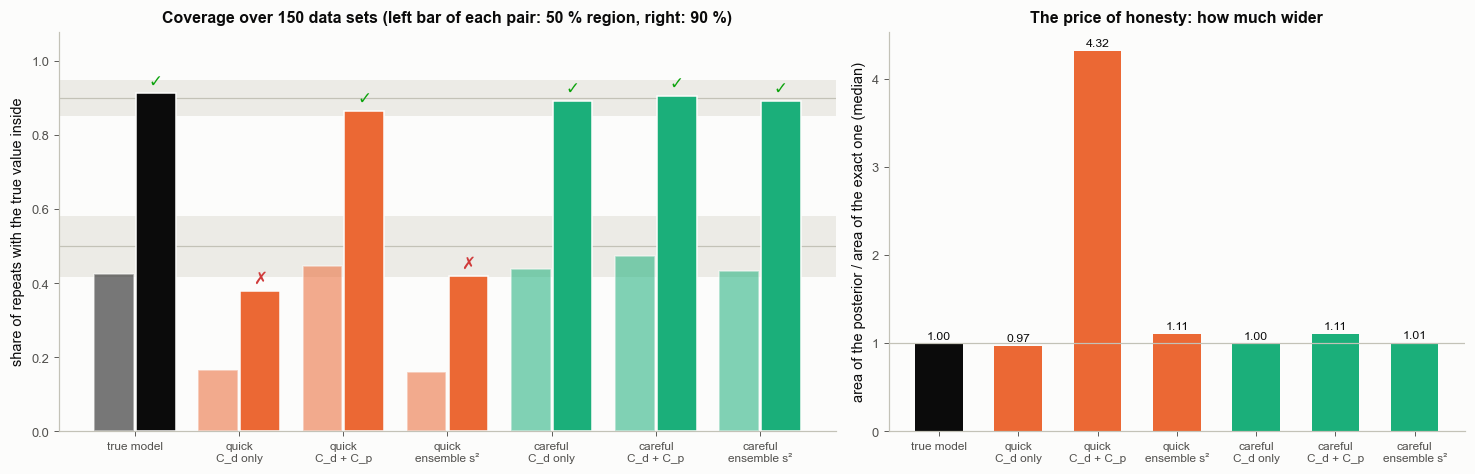

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.4), gridspec_kw=dict(width_ratios=[1.35, 1]))
labs = list(SUMM)
xs = np.arange(len(labs))
cols = [C_TRUE] + [C_Q] * 3 + [C_C] * 3
hatches = [""] + ["", "//", ".."] * 2
ax = axs[0]
for q_, off, alpha in ((0.5, -0.2, 0.55), (0.9, 0.2, 1.0)):
    v = [SUMM[l][f"c{int(q_ * 100)}"] for l in labs]
    ax.bar(xs + off, v, width=0.38, color=cols, alpha=alpha, hatch=None, edgecolor=S.SURFACE)
    ax.axhspan(q_ - se2(q_), q_ + se2(q_), color="#ecebe6", lw=0, zorder=0)
    ax.axhline(q_, color=S.AXIS, lw=0.8, zorder=0)
for i, l in enumerate(labs):
    ok = abs(SUMM[l]["c90"] - 0.9) <= se2(0.9)
    ax.text(i + 0.2, SUMM[l]["c90"] + 0.02, "✓" if ok else "✗", ha="center", color=S.GOOD if ok else S.BAD, fontsize=11)
ax.set_xticks(xs); ax.set_xticklabels([l.replace(", ", "\n") for l in labs], fontsize=7.8)
ax.set_ylim(0, 1.08); ax.set_ylabel("share of repeats with the true value inside")
ax.set_title(f"Coverage over {NREP} data sets (left bar of each pair: 50 % region, right: 90 %)")
ax = axs[1]
ax.bar(xs, [SUMM[l]["area"] for l in labs], color=cols, width=0.6)
ax.axhline(1, color=S.AXIS, lw=0.8)
ax.set_xticks(xs); ax.set_xticklabels([l.replace(", ", "\n") for l in labs], fontsize=7.8)
for i, l in enumerate(labs):
    ax.text(i, SUMM[l]["area"] + 0.05, f"{SUMM[l]['area']:.2f}", ha="center", fontsize=8)
ax.set_ylabel("area of the posterior / area of the exact one (median)")
ax.set_title("The price of honesty: how much wider")
fig.tight_layout()
bk.savefig(fig, "3-07_coverage")
plt.show()

**How to read it.** Left: the grey bands are the scatter expected from 150 repeats around 50 % and 90 %; a ✓ marks a
90 % count inside its band. The true model is the reference. Right: how much larger each posterior is than the
expensive model's (median over repeats).
* **Careful surrogate**: all three likelihoods match the true model in coverage and size (numbers printed). When the
  surrogate error is far below the noise, inflation costs nothing and changes nothing.
* **Quick surrogate, $\mathbf C_d$ only**: the counts collapse, because the posterior keeps its size but moves
  (the printed median distance from the true-model mean).
* **Quick surrogate, $\mathbf C_d + \mathbf C_p$**: the counts return close to 50 % and 90 %, and the regions are
  several times larger (right). The surrogate's error has been turned into honest uncertainty, not removed.
* **Quick surrogate, ensemble $s^2$**: hardly better than no inflation. The five networks share the same training
  runs and the same smooth bias, so they partly agree with each other while all being wrong; their disagreement is
  smaller than their common error (both printed for the validation runs) and, unlike $\mathbf C_p$, it has no
  correlation between epochs. 3.02, section 11, saw the spread fall short of the error out of distribution.

**The image to keep.** A surrogate posterior is honest only if the likelihood carries the surrogate's error, and
that error must be measured against the true model (validation runs), not guessed from the surrogate itself.

**Common misreadings.**
* "Inflation recovers the true posterior." It recovers coverage, at the price of width. Only better training (the
  careful surrogate) recovers the posterior itself.
* "An ensemble's spread is an error bar." It is the spread among models that fit the same runs (3.02, section 11).

## 4. Delayed acceptance: use the surrogate, let the true model decide

**In plain words.** Section 3 made the surrogate's posterior honest by widening it. A different idea keeps the
exact posterior and uses the surrogate only to save runs. In Metropolis sampling most proposals are rejected, and each
rejection costs a true-model run. Let the surrogate screen every proposal first: a proposal the surrogate already
dislikes is thrown away for free, and only promising ones are passed on to the true model, which has the final word.
A wrong surrogate then wastes runs; it cannot bias the answer.

**Precisely.** Delayed-acceptance Metropolis-Hastings (Christen & Fox 2005, cited for the idea only). With a symmetric
proposal $\mathbf y \sim q(\cdot\mid\mathbf x)$, a surrogate posterior $\hat\pi$ and the true posterior $\pi$:

$$\text{stage 1: accept with } \alpha_1 = \min\Big(1, \frac{\hat\pi(\mathbf y)}{\hat\pi(\mathbf x)}\Big),\qquad
\text{stage 2 (only if stage 1 accepted): accept with } \alpha_2 = \min\Big(1, \frac{\pi(\mathbf y)\,\hat\pi(\mathbf x)}{\pi(\mathbf x)\,\hat\pi(\mathbf y)}\Big).$$

The two stages together satisfy detailed balance (2.16) with respect to $\pi$, so the chain samples the exact posterior
whatever $\hat\pi$ is (it only has to be positive where $\pi$ is). True-model runs are spent only in stage 2.
A stronger variant replaces the single proposal by a **subchain**: run $n_\text{sub}$ Metropolis steps on $\hat\pi$
starting from $\mathbf x$ and propose where the subchain ends; the same stage-2 ratio accepts or rejects it. This is the
two-level case of multilevel delayed acceptance (MLDA; Lykkegaard et al. 2023, as cited by Niu et al.; section 8).
All chains here use the same Gaussian random-walk proposal, with covariance $2.38^2/2$ times the covariance of the
surrogate's posterior (so the surrogate also sets the step size), 4 chains, started near the exact mean.

The code of the two samplers:

In [7]:
def counted(ll, d):
    """ln-likelihood on a batch of points, with a counter of the points evaluated (= model runs)."""
    c = {"n": 0}
    dj = jnp.asarray(d)

    def f(U):
        c["n"] += len(U)
        return np.array(ll(jnp.asarray(U), dj))
    return f, c


def delayed_acceptance(ll_sur, ll_tru, d, n, Lp, x0, rng):
    """Christen & Fox (2005) two-stage Metropolis-Hastings, vectorised over chains. Returns draws and run counts."""
    fs, cs = counted(ll_sur, d)
    ft, ct = counted(ll_tru, d)
    x = x0.copy(); C = len(x)
    lx, sx = ft(x), fs(x)
    out, n1, n2 = np.empty((C, n, 2)), 0, 0
    for i in range(n):
        y = x + rng.standard_normal((C, 2)) @ Lp.T
        sy = fs(y)
        a1 = np.log(rng.random(C)) < sy - sx                     # stage 1: the surrogate screens (free)
        if a1.any():
            ly = np.full(C, -np.inf)
            ly[a1] = ft(y[a1])                                    # stage 2: true-model runs only for the survivors
            a2 = a1 & (np.log(rng.random(C)) < (ly - lx) - (sy - sx))
            x[a2], lx[a2], sx[a2] = y[a2], ly[a2], sy[a2]
            n1 += a1.sum(); n2 += a2.sum()
        out[:, i] = x
    return out, dict(true=ct["n"], sur=cs["n"], stage1=n1 / (n * C), stage2=n2 / max(n1, 1))


def two_level(ll_sur, ll_tru, d, n, n_sub, Lp, x0, rng):
    """Two-level delayed acceptance: a Metropolis subchain on the surrogate proposes, the true model accepts."""
    fs, cs = counted(ll_sur, d)
    ft, ct = counted(ll_tru, d)
    x = x0.copy(); C = len(x)
    lx, sx = ft(x), fs(x)
    out, acc = np.empty((C, n, 2)), 0
    for i in range(n):
        y, sy = x.copy(), sx.copy()
        for _ in range(n_sub):                                   # subchain on the surrogate posterior (free)
            z = y + rng.standard_normal((C, 2)) @ Lp.T
            sz = fs(z)
            a = np.log(rng.random(C)) < sz - sy
            y[a], sy[a] = z[a], sz[a]
        ly = ft(y)                                                # one true-model run per outer step
        a2 = np.log(rng.random(C)) < (ly - lx) - (sy - sx)
        x[a2], lx[a2], sx[a2] = y[a2], ly[a2], sy[a2]
        acc += a2.sum()
        out[:, i] = x
    return out, dict(true=ct["n"], sur=cs["n"], stage2=acc / (n * C))


def metropolis_true(ll_tru, d, n, Lp, x0, rng):
    """Plain random-walk Metropolis on the true model: every proposal is a run."""
    ft, ct = counted(ll_tru, d)
    x = x0.copy(); C = len(x)
    lx = ft(x)
    out = np.empty((C, n, 2))
    for i in range(n):
        y = x + rng.standard_normal((C, 2)) @ Lp.T
        ly = ft(y)
        a = np.log(rng.random(C)) < ly - lx
        x[a], lx[a] = y[a], ly[a]
        out[:, i] = x
    return out, dict(true=ct["n"])


print(inspect.getsource(delayed_acceptance))

def delayed_acceptance(ll_sur, ll_tru, d, n, Lp, x0, rng):
    """Christen & Fox (2005) two-stage Metropolis-Hastings, vectorised over chains. Returns draws and run counts."""
    fs, cs = counted(ll_sur, d)
    ft, ct = counted(ll_tru, d)
    x = x0.copy(); C = len(x)
    lx, sx = ft(x), fs(x)
    out, n1, n2 = np.empty((C, n, 2)), 0, 0
    for i in range(n):
        y = x + rng.standard_normal((C, 2)) @ Lp.T
        sy = fs(y)
        a1 = np.log(rng.random(C)) < sy - sx                     # stage 1: the surrogate screens (free)
        if a1.any():
            ly = np.full(C, -np.inf)
            ly[a1] = ft(y[a1])                                    # stage 2: true-model runs only for the survivors
            a2 = a1 & (np.log(rng.random(C)) < (ly - lx) - (sy - sx))
            x[a2], lx[a2], sx[a2] = y[a2], ly[a2], sy[a2]
            n1 += a1.sum(); n2 += a2.sum()
        out[:, i] = x
    return out, dict(true=ct["n"], sur=cs["n"], stage1=n1 / (n * C), stage2=n2 / max(n1, 1))



In [8]:
DA = {}
t0 = time.time()
x0 = EX["m"] + sd_ex * np.random.default_rng(3).standard_normal((4, 2))
for name in ("quick", "careful"):
    ll_s = ll_surrogate(SUR[name]["pred"], "none")
    ps = make_posterior(ll_s)(d0)
    Lp = np.linalg.cholesky(2.38 ** 2 / 2 * ps["C"])           # proposal shaped by the surrogate's posterior
    runs = {f"Metropolis, true model": metropolis_true(ll_true, d0, 4000, Lp, x0, np.random.default_rng(11)),
            f"delayed acceptance": delayed_acceptance(ll_s, ll_true, d0, 4000, Lp, x0, np.random.default_rng(12)),
            f"two-level, subchain of 10": two_level(ll_s, ll_true, d0, 800, 10, Lp, x0, np.random.default_rng(13))}
    for lab, (draws, info) in runs.items():
        g = grade(draws[:, draws.shape[1] // 10:])               # drop the first 10 % as warm-up
        DA[(name, lab)] = dict(draws=draws, **info, **g, ntrain=SUR[name]["n"])
        extra = (f"; stage-1 pass rate {info['stage1']:.2f}, stage-2 acceptance {info['stage2']:.2f}" if "stage1" in info
                 else (f"; stage-2 acceptance {info['stage2']:.2f}" if "stage2" in info else ""))
        print(f"{name:8s} surrogate | {lab:27s}: true-model runs {info['true']:6d}; R-hat {g['rhat']:.3f}, ESS {g['ess']:6.0f}, "
              f"ESS per 1000 runs {1000 * g['ess'] / info['true']:6.1f}; mean shift {np.round(g['shift'], 2)} exact sd, "
              f"sd ratio {np.round(g['sdr'], 2)}, inside exact 90 % {g['in90']:.2f}{extra}")
print(f"delayed-acceptance runs: {time.time() - t0:.0f} s")
for name in ("quick", "careful"):
    for lab in ("delayed acceptance", "two-level, subchain of 10"):
        r = DA[(name, lab)]
        print(f"{name:8s} | {lab:27s}: ESS per 1000 runs including the {FIRST[name]} runs spent before the data "
              f"(pilot, validation, training): {1000 * r['ess'] / (r['true'] + FIRST[name]):6.1f}")
print("note: the Metropolis chains on the true model use the same proposal, shaped by the surrogate's posterior; without "
      "a surrogate that tuning would cost extra true-model runs, not counted here")

quick    surrogate | Metropolis, true model     : true-model runs  16004; R-hat 1.003, ESS   1291, ESS per 1000 runs   80.6; mean shift [0.02 0.02] exact sd, sd ratio [1.03 1.03], inside exact 90 % 0.89
quick    surrogate | delayed acceptance         : true-model runs   5291; R-hat 1.002, ESS    662, ESS per 1000 runs  125.1; mean shift [0.08 0.09] exact sd, sd ratio [0.98 0.98], inside exact 90 % 0.90; stage-1 pass rate 0.33, stage-2 acceptance 0.64
quick    surrogate | two-level, subchain of 10  : true-model runs   3204; R-hat 1.004, ESS    325, ESS per 1000 runs  101.4; mean shift [0.11 0.11] exact sd, sd ratio [1.02 1.02], inside exact 90 % 0.89; stage-2 acceptance 0.56


careful  surrogate | Metropolis, true model     : true-model runs  16004; R-hat 1.003, ESS   1641, ESS per 1000 runs  102.6; mean shift [0.   0.01] exact sd, sd ratio [1.01 1.01], inside exact 90 % 0.89
careful  surrogate | delayed acceptance         : true-model runs   5000; R-hat 1.002, ESS   1695, ESS per 1000 runs  339.0; mean shift [-0.03 -0.02] exact sd, sd ratio [0.97 0.98], inside exact 90 % 0.90; stage-1 pass rate 0.31, stage-2 acceptance 0.95
careful  surrogate | two-level, subchain of 10  : true-model runs   3204; R-hat 1.001, ESS   2164, ESS per 1000 runs  675.4; mean shift [0.04 0.04] exact sd, sd ratio [0.97 0.97], inside exact 90 % 0.89; stage-2 acceptance 0.95
delayed-acceptance runs: 4 s
quick    | delayed acceptance         : ESS per 1000 runs including the 900 runs spent before the data (pilot, validation, training):  106.9
quick    | two-level, subchain of 10  : ESS per 1000 runs including the 900 runs spent before the data (pilot, validation, training):   79.2
care

saved figures/3-07_delayed_acceptance.png


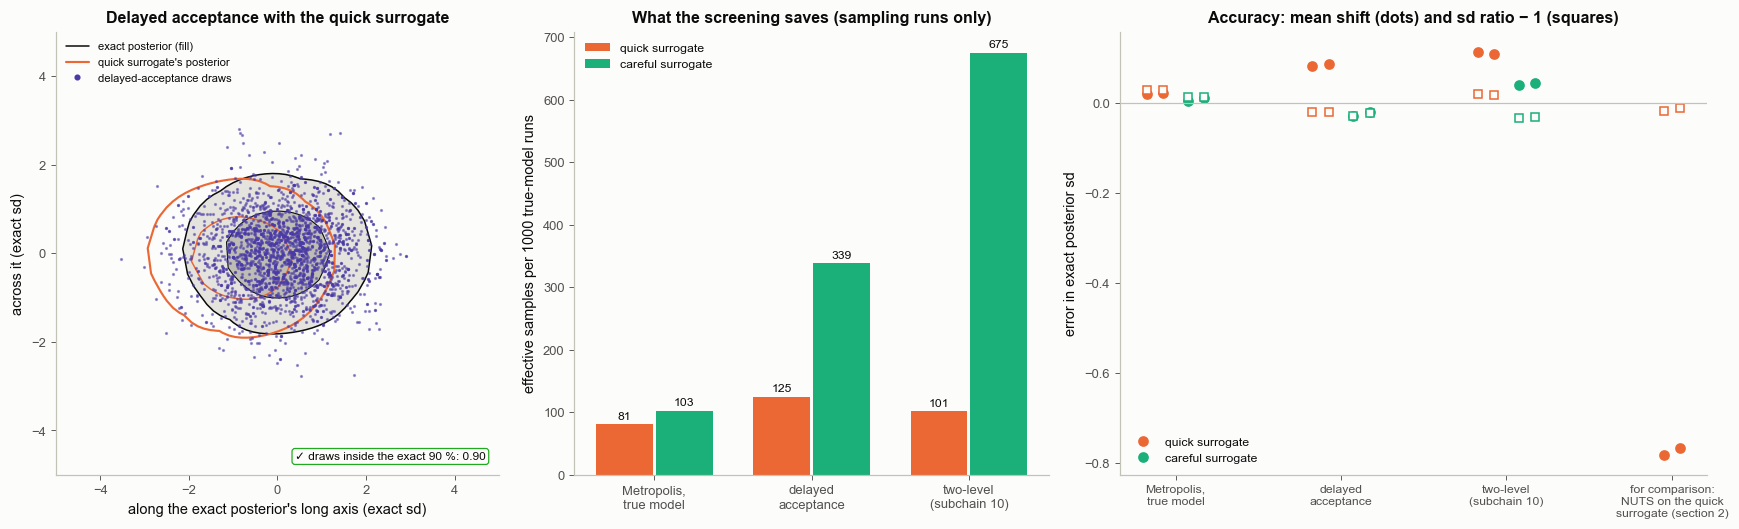

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(16.0, 4.9), gridspec_kw=dict(width_ratios=[1, 1.05, 1.3]))
ax = axs[0]
hdr_contour(ax, EX, C_TRUE, lw=1.0, fill=True)
hdr_contour(ax, post_q, C_Q, lw=1.4, zorder=3)
X = whiten(DA[("quick", "delayed acceptance")]["draws"][:, 400::6].reshape(-1, 2))
ax.plot(X[:, 0], X[:, 1], ".", color=S.VIOLET, ms=2.2, alpha=0.5, zorder=4)
ax.set_xlim(-5, 5); ax.set_ylim(-5, 5); ax.set_aspect("equal")
ax.set_xlabel("along the exact posterior's long axis (exact sd)"); ax.set_ylabel("across it (exact sd)")
ax.set_title("Delayed acceptance with the quick surrogate")
ax.legend(handles=[Line2D([], [], color=C_TRUE, lw=1.0, label="exact posterior (fill)"),
                   Line2D([], [], color=C_Q, lw=1.4, label="quick surrogate's posterior"),
                   Line2D([], [], color=S.VIOLET, marker=".", ls="", label="delayed-acceptance draws")],
          fontsize=7.4, loc="upper left")
g = DA[("quick", "delayed acceptance")]
S.badge(ax, f"draws inside the exact 90 %: {g['in90']:.2f}", ok=abs(g["in90"] - 0.9) < 0.05, loc="lower right", fs=7.8)
labs = ["Metropolis, true model", "delayed acceptance", "two-level, subchain of 10"]
short = ["Metropolis,\ntrue model", "delayed\nacceptance", "two-level\n(subchain 10)"]
ax = axs[1]
w = 0.38
for k, (name, col) in enumerate((("quick", C_Q), ("careful", C_C))):
    v = [1000 * DA[(name, l)]["ess"] / DA[(name, l)]["true"] for l in labs]
    ax.bar(np.arange(3) + (k - 0.5) * w, v, width=w * 0.95, color=col, label=f"{name} surrogate")
    for i, vv in enumerate(v):
        ax.text(i + (k - 0.5) * w, vv + 8, f"{vv:.0f}", ha="center", fontsize=8)
ax.set_xticks(range(3)); ax.set_xticklabels(short, fontsize=8.5)
ax.set_ylabel("effective samples per 1000 true-model runs")
ax.set_title("What the screening saves (sampling runs only)")
ax.legend(fontsize=8, loc="upper left")
ax = axs[2]
for k, (name, col) in enumerate((("quick", C_Q), ("careful", C_C))):
    for i, l in enumerate(labs):
        r = DA[(name, l)]
        ax.plot(i + (k - 0.5) * 0.25 + np.array([-0.05, 0.05]), r["shift"], "o", color=col, ms=6)
        ax.plot(i + (k - 0.5) * 0.25 + np.array([-0.05, 0.05]), r["sdr"] - 1, "s", color=col, ms=5, mfc=S.SURFACE)
ng = NUTS_RES["quick surrogate"]
ax.plot([3 - 0.05, 3 + 0.05], ng["shift"], "o", color=C_Q, ms=6)
ax.plot([3 - 0.05, 3 + 0.05], ng["sdr"] - 1, "s", color=C_Q, ms=5, mfc=S.SURFACE)
ax.axhline(0, color=S.AXIS, lw=0.8)
ax.set_xticks(range(4)); ax.set_xticklabels(short + ["for comparison:\nNUTS on the quick\nsurrogate (section 2)"], fontsize=8)
ax.set_ylabel("error in exact posterior sd")
ax.set_title("Accuracy: mean shift (dots) and sd ratio − 1 (squares)")
ax.legend(handles=[Line2D([], [], color=C_Q, marker="o", ls="", label="quick surrogate"),
                   Line2D([], [], color=C_C, marker="o", ls="", label="careful surrogate")], fontsize=8, loc="lower left")
fig.tight_layout()
bk.savefig(fig, "3-07_delayed_acceptance")
plt.show()

**How to read it.** Left (same coordinates as in section 2): the quick surrogate's posterior (orange) is off the exact one (grey), as in section 2, yet
the delayed-acceptance draws (violet) fill the grey region: the true model's stage-2 test removed the surrogate's
bias. Middle: effective samples of the exact posterior per 1,000 true-model runs during sampling (printed values on
the bars). With the careful surrogate, screening multiplies the yield of plain Metropolis several times, and the
subchain more than that, because the surrogate's verdict almost always agrees with the true model's (stage-2
acceptance printed). With the quick surrogate, the gain shrinks: stage 2 rejects many of the proposals that the
surrogate liked, and each rejection was a paid run. Right: every delayed-acceptance chain is centred on the exact
posterior with the right width (all symbols near zero, R-hat printed); NUTS on the quick surrogate (section 2) is
shown for contrast.

The printed totals add every run spent before the data (pilot, validation and training). The Metropolis chains on the
true model borrowed their proposal shape from the surrogate's posterior; without a surrogate, tuning that proposal
would cost extra true-model runs, not counted here. In two dimensions a well-tuned Metropolis on the true model is already
efficient (notebook 2.18 found the same), so the absolute numbers are modest; the ratio is what carries over, and it is
set by how often the surrogate and the true model disagree.

**The image to keep.** A surrogate can be used without being trusted: let it propose and screen, let the expensive model
accept. The surrogate's quality then decides the cost, not the answer.

**Common misreadings.**
* "Delayed acceptance needs a good surrogate to be correct." It needs one to be cheap; it is correct with any
  surrogate that is positive wherever the posterior is.
* "Every proposal still costs a run." Only those that pass stage 1 (the pass rate is printed).

## 5. Amortised inference: train once, answer every data set

**In plain words.** Sections 2-4 each start over when a new data set arrives. An **amortised** network learns the
inverse map once: shown many simulated pairs (true parameters, data they would produce), it learns to output the
posterior for any data set directly, in microseconds. The cost moves entirely before the data: the simulations.
This is what real-time systems want, and it needs two checks: is the network's posterior calibrated, and how much
sharper is the exact one?

**Precisely.** Neural posterior estimation (simulation-based inference). Draw $\mathbf u_i$ from the prior and
$\mathbf d_i = \mathbf f(\mathbf u_i) + \mathbf e_i$ (prior-predictive simulations); train a network that maps
$\mathbf d$ to the parameters of a density $q_\phi(\mathbf u\mid\mathbf d)$ by minimising
$-\frac1N\sum_i \ln q_\phi(\mathbf u_i\mid\mathbf d_i)$. Its minimiser over all densities is the true posterior
(the expected KL divergence $\mathrm{E}_{\mathbf d}\,D_\text{KL}(p(\cdot\mid\mathbf d)\,\|\,q)$, the mass-covering direction of 2.28,
differs from this loss by a constant), so in the limit of a flexible enough network and enough simulations the result
is calibrated. Our network: input the data's first $K$ principal-component coefficients in noise units (the pilot
basis of section 2), two tanh layers of 128, and as output the weights, means and covariances of a mixture of three
Gaussians (a **mixture-density network**) in $\text{logit}(\mathbf u) = \ln[\mathbf u/(1-\mathbf u)]$, which maps the unit
box onto the whole plane, so every draw stays inside the prior box (the logit transform: 2.11, section 3). 50,000 simulations, 10,000 Adam steps on mini-batches of 512, trained from
two random initialisations on the same simulations. **Simulation-based calibration** (2.32, section 5) tests it: for
1,000 new simulations, the rank of the true value among 99 draws from $q$ must be uniform.

In [10]:
NC = 3                                                          # mixture components
LOGIT = lambda u: jnp.log(u) - jnp.log1p(-u)
V_in, mu_in = jnp.asarray(VT_b[:K]), jnp.asarray(MU_b)
features = lambda D: (D - mu_in) @ V_in.T / SIG                 # data -> K principal-component coefficients, noise units


def mdn_unpack(o):
    o = o.reshape(o.shape[0], NC, 6)
    return o[..., 0], o[..., 1:3], o[..., 3], o[..., 4], o[..., 5]   # weight logits, means, log-sd 1, log-sd 2, coupling


def mdn_logq(o, Z):
    """ln q(z) for a mixture of NC Gaussians with lower-triangular factors [[e^l1, 0], [c, e^l2]]."""
    w, mu, l1, l2, c = mdn_unpack(o)
    r1 = (Z[:, None, 0] - mu[..., 0]) * jnp.exp(-l1)
    r2 = (Z[:, None, 1] - mu[..., 1] - c * r1) * jnp.exp(-l2)
    lc = -0.5 * (r1 ** 2 + r2 ** 2) - l1 - l2 - jnp.log(2 * jnp.pi)
    return jax.scipy.special.logsumexp(lc + jax.nn.log_softmax(w, -1), -1)


def npe_train(D, U, seed, steps=10000, width=128, batch=512, lr=3e-3):
    F = np.asarray(features(jnp.asarray(D)))
    fm, fsd = F.mean(0), F.std(0)
    X, Z, n = jnp.asarray((F - fm) / fsd), LOGIT(jnp.asarray(U)), len(U)
    nll = lambda p, Xb, Zb: -jnp.mean(mdn_logq(mlp(p, Xb), Zb))
    p0 = init_mlp(jax.random.PRNGKey(seed), [K, width, width, NC * 6])
    keys = jax.random.split(jax.random.PRNGKey(seed + 100), steps)

    def step(carry, inp):                                        # Adam on random mini-batches (3.02)
        p, m, v = carry
        i, k = inp
        idx = jax.random.randint(k, (batch,), 0, n)
        L, g = jax.value_and_grad(nll)(p, X[idx], Z[idx])
        t = i + 1.0
        lr_t = lr * 0.5 * (1 + jnp.cos(jnp.pi * i / steps))
        m = jax.tree.map(lambda m_, g_: 0.9 * m_ + 0.1 * g_, m, g)
        v = jax.tree.map(lambda v_, g_: 0.999 * v_ + 0.001 * g_ ** 2, v, g)
        p = jax.tree.map(lambda p_, m_, v_: p_ - lr_t * (m_ / (1 - 0.9 ** t)) / (jnp.sqrt(v_ / (1 - 0.999 ** t)) + 1e-8),
                         p, m, v)
        return (p, m, v), L
    z = jax.tree.map(jnp.zeros_like, p0)
    (p, _, _), hist = jax.jit(lambda p_: jax.lax.scan(step, (p_, z, z), (jnp.arange(steps, dtype=jnp.float64), keys)))(p0)
    return jax.jit(lambda D_: mlp(p, (features(D_) - fm) / fsd)), np.asarray(hist)


def q_sample(net, D, n, rng):
    """n draws from the amortised posterior for each data set in D (len(D), 40) -> (len(D), n, 2), unit box."""
    w, mu, l1, l2, c = (np.asarray(a) for a in mdn_unpack(net(jnp.asarray(np.atleast_2d(D)))))
    pw = np.exp(w - w.max(1, keepdims=True))
    pw /= pw.sum(1, keepdims=True)
    k = np.minimum((rng.random((len(pw), n, 1)) > np.cumsum(pw, 1)[:, None, :]).sum(-1), NC - 1)
    tk = lambda a: np.take_along_axis(a, k, 1)
    e = rng.standard_normal((len(pw), n, 2))
    z1 = tk(mu[..., 0]) + np.exp(tk(l1)) * e[..., 0]
    z2 = tk(mu[..., 1]) + tk(c) * e[..., 0] + np.exp(tk(l2)) * e[..., 1]
    return 1 / (1 + np.exp(-np.stack([z1, z2], -1)))


N_SIM = 50000
rs = np.random.default_rng(2024)
U_sim = rs.uniform(size=(N_SIM, 2))
D_sim = run_true(U_sim) + SIG * rs.standard_normal((N_SIM, 40))   # prior-predictive simulations: 50,000 true-model runs
NETS, HIST = {}, {}
for seed in (0, 1):
    t0 = time.time()
    NETS[seed], HIST[seed] = npe_train(D_sim, U_sim, seed)
    print(f"amortised network, initialisation {seed}: trained in {time.time() - t0:.0f} s; final loss "
          f"{HIST[seed][-200:].mean():.3f} (mean over the last 200 steps)")
net = NETS[0]
net(jnp.asarray(d0[None])).block_until_ready()
t0 = time.time()
for _ in range(1000):
    net(jnp.asarray(d0[None])).block_until_ready()
T_NET = (time.time() - t0) / 1000
print(f"one posterior from the network: {1e6 * T_NET:.0f} microseconds (mixture parameters; drawing samples is extra and cheap)")

# main data set and the 150 repeats of section 3 (all from the true model: the network's training distribution)
S0 = q_sample(net, d0, 4000, np.random.default_rng(0))[0]
print(f"main data set: amortised mean shift {np.round((S0.mean(0) - EX['m']) / sd_ex, 2)} exact sd, "
      f"sd ratio {np.round(S0.std(0) / sd_ex, 2)}, share of draws inside the exact 90 % region {inside90(EX, S0).mean():.2f}")
Sq = q_sample(net, D_rep, 2000, np.random.default_rng(1))
sd_q = Sq.std(1)
sd_x = np.array([np.sqrt(np.diag(r["C"])) for r in ref])
dist_q = np.array([np.sqrt((Sq[j].mean(0) - r["m"]) @ np.linalg.solve(r["C"], Sq[j].mean(0) - r["m"])) for j, r in enumerate(ref)])
print(f"over the {NREP} repeats of section 3: median sd ratio (amortised / exact) {np.round(np.median(sd_q / sd_x, 0), 2)}; "
      f"median distance between the amortised and the exact mean {np.median(dist_q):.2f} exact sd")
rat = (sd_q / sd_x).ravel()
srt = np.argsort((sd_x * (HI - LO)).ravel())
third = len(srt) // 3
print(f"sd ratio, narrowest third of the exact posteriors: median {np.median(rat[srt[:third]]):.2f}, largest {rat[srt[:third]].max():.1f}; "
      f"broadest third: median {np.median(rat[srt[-third:]]):.2f}, largest {rat[srt[-third:]].max():.1f}")


def sbc(net, U_t, D_t, rng, L=99, NB=20):
    """Ranks of the true values among L draws of the amortised posterior; chi-square test of uniformity per parameter."""
    Sm = q_sample(net, D_t, L, rng)
    out = []
    for i in range(2):
        rk = (Sm[..., i] < U_t[:, None, i]).sum(1)
        h = np.histogram(rk, bins=np.arange(0, L + 2, (L + 1) // NB) - 0.5)[0]
        out.append((h, chisquare(h).pvalue))
    return out


rt = np.random.default_rng(5)
U_sbc = rt.uniform(size=(1000, 2))
E_sbc = SIG * rt.standard_normal((1000, 40))
D_sbc = run_true(U_sbc) + E_sbc
SBC = {"well specified": sbc(net, U_sbc, D_sbc, np.random.default_rng(6))}
sbc1 = sbc(NETS[1], U_sbc, D_sbc, np.random.default_rng(6))
print("SBC, 1,000 simulations, chi-square p-values (ln a_sigma, ln v0): initialisation 0: "
      f"{SBC['well specified'][0][1]:.3g}, {SBC['well specified'][1][1]:.3g};  initialisation 1: {sbc1[0][1]:.3g}, {sbc1[1][1]:.3g}")
print(f"ledger: {N_SIM:,} simulation runs plus the {N_SHARED} pilot and validation runs (input basis and K) before any "
      f"data; then 0 runs per data set (NUTS on the true model used {steps_true:,} runs with gradients for one data set, "
      f"section 2)")

amortised network, initialisation 0: trained in 13 s; final loss -3.339 (mean over the last 200 steps)


amortised network, initialisation 1: trained in 12 s; final loss -3.356 (mean over the last 200 steps)
one posterior from the network: 47 microseconds (mixture parameters; drawing samples is extra and cheap)
main data set: amortised mean shift [-0.34 -0.33] exact sd, sd ratio [1.75 1.74], share of draws inside the exact 90 % region 0.52


over the 150 repeats of section 3: median sd ratio (amortised / exact) [1.66 2.02]; median distance between the amortised and the exact mean 1.44 exact sd
sd ratio, narrowest third of the exact posteriors: median 1.66, largest 80.8; broadest third: median 1.64, largest 10.7
SBC, 1,000 simulations, chi-square p-values (ln a_sigma, ln v0): initialisation 0: 0.23, 0.735;  initialisation 1: 0.0605, 0.332
ledger: 50,000 simulation runs plus the 800 pilot and validation runs (input basis and K) before any data; then 0 runs per data set (NUTS on the true model used 81,700 runs with gradients for one data set, section 2)


saved figures/3-07_amortised.png


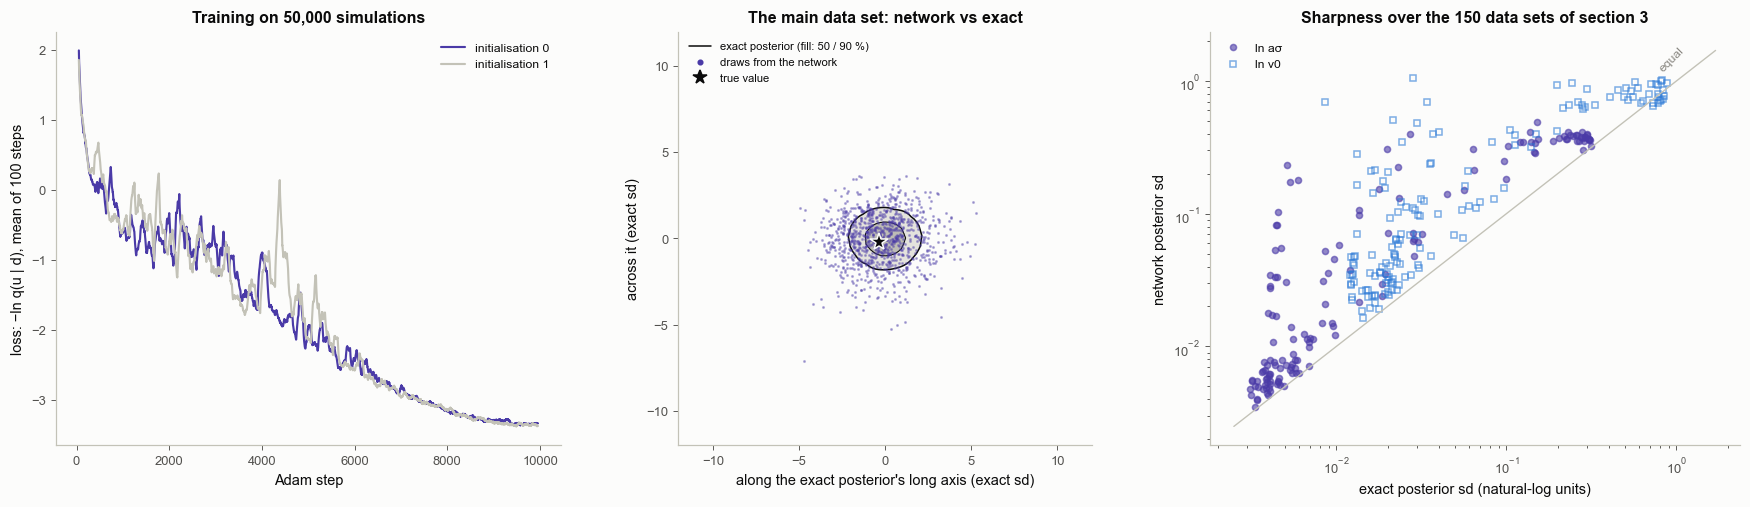

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(16.0, 4.7), gridspec_kw=dict(width_ratios=[1, 1, 1.05]))
ax = axs[0]
for seed, col in ((0, S.VIOLET), (1, S.AXIS)):
    h = HIST[seed]
    sm = np.convolve(h, np.ones(100) / 100, mode="valid")
    ax.plot(np.arange(len(sm)) + 50, sm, color=col, lw=1.4, label=f"initialisation {seed}")
ax.set_xlabel("Adam step"); ax.set_ylabel("loss: −ln q(u | d), mean of 100 steps")
ax.set_title("Training on 50,000 simulations")
ax.legend(fontsize=8)
ax = axs[1]
hdr_contour(ax, EX, C_TRUE, lw=1.0, fill=True)
X = whiten(S0[::4])
ax.plot(X[:, 0], X[:, 1], ".", color=S.VIOLET, ms=2.0, alpha=0.35, zorder=4)
ax.plot(*whiten(U0)[0], "*", color=S.INK, ms=12, mec=S.SURFACE, zorder=6)
ax.set_xlim(-12, 12); ax.set_ylim(-12, 12); ax.set_aspect("equal")
ax.set_xlabel("along the exact posterior's long axis (exact sd)"); ax.set_ylabel("across it (exact sd)")
ax.set_title("The main data set: network vs exact")
ax.legend(handles=[Line2D([], [], color=C_TRUE, lw=1.0, label="exact posterior (fill: 50 / 90 %)"),
                   Line2D([], [], color=S.VIOLET, marker=".", ls="", label="draws from the network"),
                   Line2D([], [], color=S.INK, marker="*", ls="", ms=9, label="true value")], fontsize=7.4, loc="upper left")
ax = axs[2]
for i, (mk, lab) in enumerate((("o", "ln aσ"), ("s", "ln v0"))):
    ax.loglog(sd_x[:, i] * (HI[i] - LO[i]), sd_q[:, i] * (HI[i] - LO[i]), mk, ms=4, color=S.VIOLET if i == 0 else S.BLUE,
              alpha=0.6, mfc="none" if i else None, label=lab)
lim = [min(sd_x.min(), sd_q.min()) * 2, max(sd_x.max(), sd_q.max()) * 8]
ax.plot(lim, lim, color=S.AXIS, lw=0.9)
ax.text(lim[1] / 1.5, lim[1] / 1.5, "equal", ha="right", va="bottom", fontsize=8, color=S.MUTED, rotation=45)
ax.set_xlabel("exact posterior sd (natural-log units)"); ax.set_ylabel("network posterior sd")
ax.set_title(f"Sharpness over the {NREP} data sets of section 3")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "3-07_amortised")
plt.show()

**How to read it.** Left: the loss falls and levels off for both initialisations (final values printed). Middle: the
network's posterior for the main data set (violet dots) against the exact one (grey), in the coordinates of section
2 (with a wider window): it covers the true value but is wider and slightly off-centre (shift and sd ratio printed).
Right: one dot per data set and parameter; dots above the line are network posteriors wider than the exact ones
(median ratios printed). The typical ratio is about the same for narrow and broad exact posteriors (medians by
thirds printed), but the largest departures, far wider than the exact posterior, are among the narrowest ones (left;
largest ratios by thirds printed), where the network must resolve a tiny region of the prior box from the data alone.

Calibration: the SBC p-values are printed for both initialisations. A p-value above 0.01 means the test detects no
departure from uniform ranks at the 1 % level (2.32's criterion); the histograms are drawn in the next figure. For
both initialisations no departure is detected, for these two parameters and 1,000 simulations. That is evidence
that the network's widths are honest on this simulator, not proof: a test of this size can miss a small departure,
and a rank test on the parameters alone cannot detect a network that ignores the data (the prior itself passes,
2.32; tests on data-dependent quantities such as the likelihood can, Modrák et al. 2023). The network is clearly
less sharp than the exact posterior. Two initialisations show that this is not one lucky training run; they do not
bound how often training fails, which would need more repeats.

**The image to keep.** An amortised network buys speed for every future data set with simulations paid in advance,
and here it is wider than the exact posterior. SBC can reveal widths that are dishonest; passing it does not show
that the width is small, or that the network uses the data well.

**Common misreadings.**
* "Passing SBC means accurate." A posterior equal to the prior passes SBC (2.32). Sharpness must be judged
  separately, against the exact answer where it can be computed.
* "One good test case validates the network." The middle panel is one draw from the right panel's cloud; SBC uses
  1,000.

## 6. When the Earth is not the simulator: misspecification

**In plain words.** The network learned the simulator. If real data contain something the simulator never produced, the
network still returns an answer, instantly and without complaint. We test two such Earths:
* **offset**: every epoch shifted by an unmodelled 6 mm (three times the noise), such as a reference-frame jump;
* **wrong Δτ**: the data made with Δτ = 3.5 MPa while the network (and the inference model) assume 3 MPa.

**Precisely.** For each Earth: SBC of the network on 1,000 data sets (the badges say whether a departure from uniform
ranks was detected); the exact posterior *of the assumed model*
on the 150 repeats of section 3 (with the same true values and noise), its coverage and the distance between the network's
mean and that exact mean; and a posterior predictive check that costs one true-model run per data set: the
$\chi^2 = \lVert\mathbf d - \mathbf f(\bar{\mathbf u})\rVert^2/\sigma^2$ of the prediction at a posterior mean
$\bar{\mathbf u}$, flagged when it exceeds the 99th percentile of $\chi^2_{40}$.

In [12]:
from scipy.stats import chi2 as CHI2
OFF, DTAU_WRONG = 6.0, 3.5
CHI_THR = CHI2.ppf(0.99, 40)


def make_data(U, E, earth):
    if earth == "wrong Δτ":
        return np.asarray(u_closed(jnp.asarray(U), dtau=DTAU_WRONG)) + E
    return run_true(U) + E + (OFF if earth == "offset" else 0.0)


E_rep = D_rep - np.asarray(f_true(jnp.asarray(U_rep)))          # the noise of section 3's repeats, reused
MIS = {}
t0 = time.time()
for earth in ("well specified", "offset", "wrong Δτ"):
    Dm = make_data(U_rep, E_rep, earth)
    exact = ref if earth == "well specified" else [post_true(Dm[j], U_rep[j]) for j in range(NREP)]
    fr = np.array([r["frac"] for r in exact])
    Sq_ = q_sample(net, Dm, 2000, np.random.default_rng(7))
    m_q = Sq_.mean(1)
    dist_ = np.array([np.sqrt((m_q[j] - r["m"]) @ np.linalg.solve(r["C"], m_q[j] - r["m"])) for j, r in enumerate(exact)])
    m_x = np.array([r["m"] for r in exact])
    chi_x = ((Dm - run_true(m_x)) ** 2).sum(1) / SIG ** 2
    chi_q = ((Dm - run_true(m_q)) ** 2).sum(1) / SIG ** 2
    if earth != "well specified":
        SBC[earth] = sbc(net, U_sbc, make_data(U_sbc, E_sbc, earth), np.random.default_rng(6))
    MIS[earth] = dict(c90=(fr <= 0.9).mean(), dist=dist_, flag_x=(chi_x > CHI_THR).mean(), flag_q=(chi_q > CHI_THR).mean())
    print(f"{earth:15s}: SBC p-values {SBC[earth][0][1]:.2g}, {SBC[earth][1][1]:.2g}; exact posterior of the assumed model "
          f"covers the true value (90 %) in {MIS[earth]['c90']:.3f} of {NREP}; median distance network-exact mean "
          f"{np.median(dist_):.2f} exact sd; predictive check flags {MIS[earth]['flag_x']:.3f} (at the exact mean), "
          f"{MIS[earth]['flag_q']:.3f} (at the network's mean)")
print(f"misspecification experiments: {time.time() - t0:.0f} s; flag threshold chi2 > {CHI_THR:.1f} (99th percentile of chi2_40)")

# why does the check flag 5 % of well-specified data sets at the exact mean, not 1 %? compare three points
chi_truth = ((D_rep - run_true(U_rep)) ** 2).sum(1) / SIG ** 2
chi_mean = ((D_rep - run_true(np.array([r["m"] for r in ref]))) ** 2).sum(1) / SIG ** 2
chi_map = ((D_rep - run_true(np.array([r["G"][np.argmax(r["p"])] for r in ref]))) ** 2).sum(1) / SIG ** 2
for nm_, c_ in [("true values", chi_truth), ("exact posterior mean", chi_mean), ("best grid point (MAP)", chi_map)]:
    print(f"well specified, check made at the {nm_:22s}: mean chi2 {c_.mean():5.2f}, flags {(c_ > CHI_THR).mean():.3f}")
print(f"chi2(mean) - chi2(MAP) over the {NREP} data sets: median {np.median(chi_mean - chi_map):.2f}, "
      f"90th percentile {np.percentile(chi_mean - chi_map, 90):.2f}, largest {np.max(chi_mean - chi_map):.2f}")

well specified : SBC p-values 0.23, 0.74; exact posterior of the assumed model covers the true value (90 %) in 0.913 of 150; median distance network-exact mean 1.68 exact sd; predictive check flags 0.053 (at the exact mean), 0.307 (at the network's mean)


offset         : SBC p-values 1.1e-27, 1.5e-292; exact posterior of the assumed model covers the true value (90 %) in 0.000 of 150; median distance network-exact mean 9.85 exact sd; predictive check flags 0.687 (at the exact mean), 0.833 (at the network's mean)


wrong Δτ       : SBC p-values 1.8e-248, 0; exact posterior of the assumed model covers the true value (90 %) in 0.020 of 150; median distance network-exact mean 6.95 exact sd; predictive check flags 0.520 (at the exact mean), 0.680 (at the network's mean)
misspecification experiments: 2 s; flag threshold chi2 > 63.7 (99th percentile of chi2_40)
well specified, check made at the true values           : mean chi2 39.88, flags 0.007
well specified, check made at the exact posterior mean  : mean chi2 41.07, flags 0.053
well specified, check made at the best grid point (MAP) : mean chi2 37.82, flags 0.007
chi2(mean) - chi2(MAP) over the 150 data sets: median -0.01, 90th percentile 13.94, largest 47.62


saved figures/3-07_amortised_sbc.png


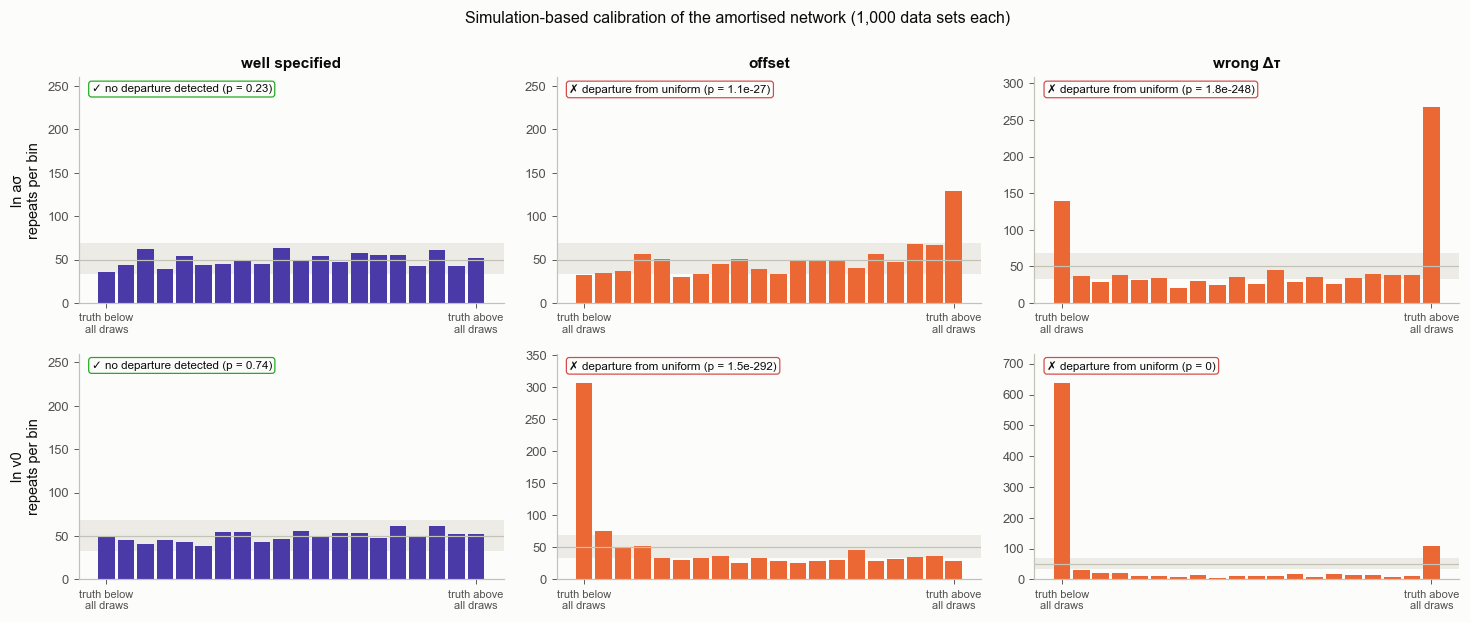

In [13]:
EARTHS = list(SBC)
fig, axs = plt.subplots(2, 3, figsize=(13.5, 5.6))
NB = 20
lo_b, hi_b = binom.ppf([0.005, 0.995], 1000, 1 / NB)
for j, earth in enumerate(EARTHS):
    for i, pname in enumerate(("ln aσ", "ln v0")):
        ax = axs[i, j]
        h, pval = SBC[earth][i]
        ax.axhspan(lo_b, hi_b, color="#ecebe6", lw=0)
        ax.axhline(1000 / NB, color=S.AXIS, lw=0.8)
        ax.bar(np.arange(NB), h, width=0.85, color=S.VIOLET if pval > 0.01 else S.ORANGE)
        S.badge(ax, f"{'no departure detected' if pval > 0.01 else 'departure from uniform'} (p = {pval:.2g})",
                ok=pval > 0.01, loc="upper left", fs=7.6)
        ax.set_ylim(0, max(260, h.max() * 1.15))
        ax.set_xticks([0, NB - 1]); ax.set_xticklabels(["truth below\nall draws", "truth above\nall draws"], fontsize=7.2)
        if i == 0:
            ax.set_title(f"{earth}", fontsize=10)
        if j == 0:
            ax.set_ylabel(f"{pname}\nrepeats per bin")
fig.suptitle("Simulation-based calibration of the amortised network (1,000 data sets each)", fontsize=10.5, y=1.0)
fig.tight_layout()
bk.savefig(fig, "3-07_amortised_sbc")
plt.show()

saved figures/3-07_misspecification.png


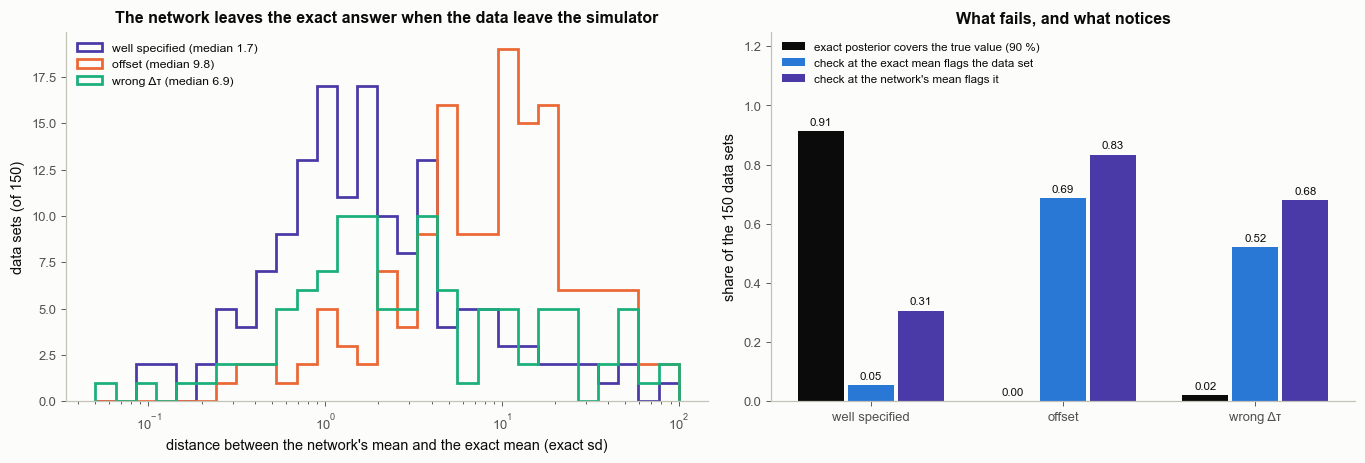

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw=dict(width_ratios=[1.1, 1]))
ax = axs[0]
bins = np.logspace(-1.3, 2, 30)
for earth, col in zip(EARTHS, (S.VIOLET, S.ORANGE, S.AQUA)):
    ax.hist(MIS[earth]["dist"], bins=bins, histtype="step", lw=1.8, color=col,
            label=f"{earth} (median {np.median(MIS[earth]['dist']):.1f})")
ax.set_xscale("log")
ax.set_xlabel("distance between the network's mean and the exact mean (exact sd)")
ax.set_ylabel(f"data sets (of {NREP})")
ax.set_title("The network leaves the exact answer when the data leave the simulator")
ax.legend(fontsize=8)
ax = axs[1]
xs = np.arange(len(EARTHS))
w = 0.26
for k, (key, lab, col) in enumerate((("c90", "exact posterior covers the true value (90 %)", S.INK),
                                     ("flag_x", "check at the exact mean flags the data set", S.BLUE),
                                     ("flag_q", "check at the network's mean flags it", S.VIOLET))):
    v = [MIS[e][key] for e in EARTHS]
    ax.bar(xs + (k - 1) * w, v, width=w * 0.92, color=col, label=lab)
    for i, vv in enumerate(v):
        ax.text(i + (k - 1) * w, vv + 0.02, f"{vv:.2f}", ha="center", fontsize=7.5)
ax.set_xticks(xs); ax.set_xticklabels(EARTHS)
ax.set_ylim(0, 1.25); ax.set_ylabel(f"share of the {NREP} data sets")
ax.set_title("What fails, and what notices")
ax.legend(fontsize=7.6, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "3-07_misspecification")
plt.show()

**How to read it.** First figure: SBC histograms for the three Earths; the grey band is where 99 % of the bins of a
uniform histogram fall. Under both misspecified Earths the ranks pile up at the ends (p-values printed): the true
value lies outside the network's posterior far too often. Second figure, left: how far the network's mean is from the
exact mean of the assumed model, in exact standard deviations; the distribution moves to the right for both
misspecified Earths (medians in the legend). Right, black bars: the exact posterior of the assumed model also fails to
cover the true value. The failure belongs to the model, and the network inherits it; leaving the training
distribution then adds the network's own extrapolation error (left). Blue and violet bars: the predictive check with
one true-model run flags many misspecified data sets, and rarely the well-specified ones when it is made at the exact
mean. Made at the network's mean, it also flags a sizeable share of the well-specified data sets, because the network's
mean is not precise enough for a sharp χ² test.

Even at the exact mean the false-alarm rate is above the nominal 1 % (printed). The last printed lines show why: at
the true values and at the best grid point the check flags about 1 %, at the exact posterior mean more. The posterior
is a thin curved ridge, and for some data sets its mean lies beside the ridge, where the fit is worse (the χ²
differences printed). This is Jensen's point from 2.32 in a new place: the mean of the parameters is not a parameter
set the data favour. Make a predictive check at the best-fitting point, or with draws from the posterior.

**The image to keep.** An amortised network answers any question instantly, including questions the simulator never
asked. Keep one true-model run per event for a predictive check, and expect the check to be only as sharp as the
point at which it is made.

**Common misreadings.**
* "SBC would catch misspecification in real data." SBC runs on simulations; it tests the network against its own
  simulator. Here we could run it on the wrong Earths only because we built them. With real data, the predictive check
  (and independent data) is what is left.
* "A wrong Δτ is absorbed into $v_0$, so it does no harm." For $\Delta\tau\gg a\sigma$ the curve depends on $v_0
  e^{\Delta\tau/a\sigma}$ (3.03, section 1), so part of it is absorbed; the coverage and flag rates printed above show
  how much is not.

## 7. The ledger, filled in

Every method of this notebook on one picture: runs of the true model spent before the data (training or simulations)
against runs spent for one data set, scaled to 1,000 effective samples of the posterior it delivers. Filled symbols
sample the exact posterior; open symbols sample an approximation, labelled with its mean shift on the main data set.

NUTS, true model                      : runs before the data      0; per data set for 1000 effective samples    119148 runs with gradients; total for one data set    119148, per data set if 100 data sets share the cost before the data    119148; exact
Metropolis, true model                : runs before the data      0; per data set for 1000 effective samples      9750 forward runs; total for one data set      9750, per data set if 100 data sets share the cost before the data      9750; exact
delayed acceptance, quick             : runs before the data    900; per data set for 1000 effective samples      7994 forward runs; total for one data set      8894, per data set if 100 data sets share the cost before the data      8003; exact
two-level, quick                      : runs before the data    900; per data set for 1000 effective samples      9857 forward runs; total for one data set     10757, per data set if 100 data sets share the cost before the data      9866; exact
NUTS on the q

saved figures/3-07_ledger.png


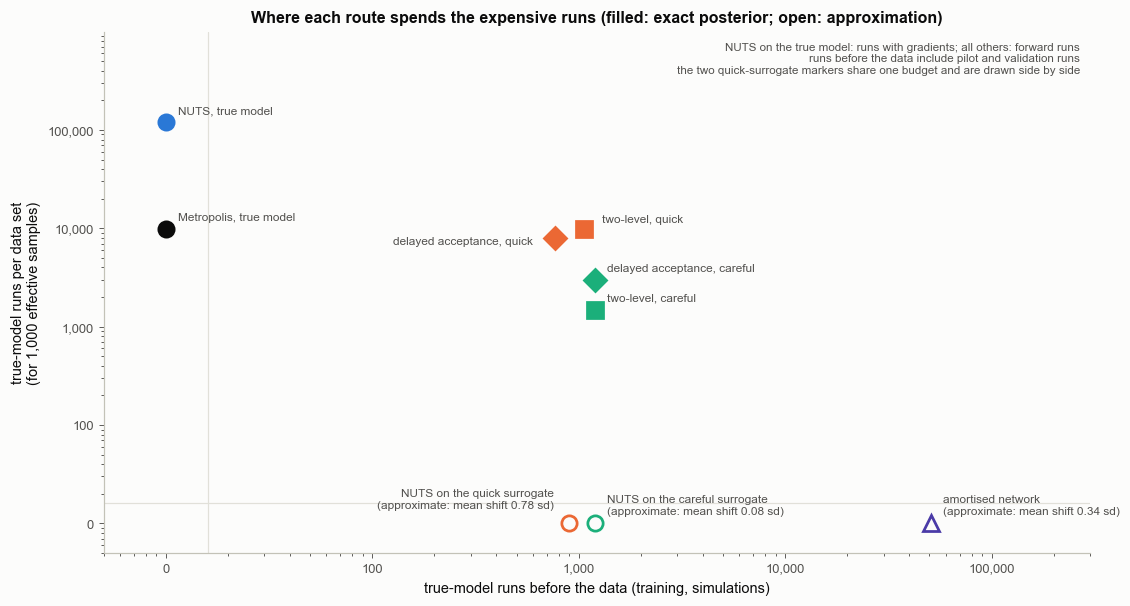

In [15]:
pts = []                                                       # (label, runs before, runs per data set per 1000 ESS, exact?, shift)
r_ = NUTS_RES["true model"]
pts.append(("NUTS, true model", 0, steps_true * 1000 / r_["ess"], True, None, C_NUTS, "o"))
r_ = DA[("careful", "Metropolis, true model")]
pts.append(("Metropolis, true model", 0, r_["true"] * 1000 / r_["ess"], True, None, S.INK, "o"))
for name, col in (("quick", C_Q), ("careful", C_C)):
    for lab, mk in (("delayed acceptance", "D"), ("two-level, subchain of 10", "s")):
        r_ = DA[(name, lab)]
        pts.append((f"{lab.split(',')[0]}, {name}", FIRST[name], r_["true"] * 1000 / r_["ess"], True, None, col, mk))
    g = NUTS_RES[f"{name} surrogate"]
    pts.append((f"NUTS on the {name} surrogate", FIRST[name], 0, False, np.abs(g["shift"]).max(), col, "o"))
N_AMORT = N_SIM + N_SHARED                                      # the network's input basis came from the pilot runs, K from validation
pts.append(("amortised network", N_AMORT, 0, False, np.abs((S0.mean(0) - EX["m"]) / sd_ex).max(), S.VIOLET, "^"))
ZERO = 10.0                                                    # where "0 runs" is drawn on the log axes
LAB_OFF = {"NUTS on the quick surrogate": ((-10, 10), "right"), "two-level, quick": ((12, 4), "left"),
           "delayed acceptance, quick": ((-14, -4), "right")}
X_NUDGE = {"two-level, quick": 1.18, "delayed acceptance, quick": 0.85}   # same budget: drawn side by side
fig, ax = plt.subplots(figsize=(10.5, 5.6))
for lab, xb, yd, exact, sh, col, mk in pts:
    x, y = max(xb, ZERO) * X_NUDGE.get(lab, 1.0), max(yd, ZERO)
    ax.plot(x, y, mk, ms=10, color=col, mfc=col if exact else S.SURFACE, mew=1.8, zorder=3)
    txt = lab + ("" if exact else f"\n(approximate: mean shift {sh:.2f} sd)")
    off, ha = LAB_OFF.get(lab, ((8, 6), "left"))
    ax.annotate(txt, (x, y), xytext=off, textcoords="offset points", fontsize=7.8, color=S.INK2, ha=ha)
    kind = ("runs with gradients" if lab.startswith("NUTS, true") else "forward runs")
    print(f"{lab:38s}: runs before the data {xb:6d}; per data set for 1000 effective samples {yd:9.0f} {kind}; "
          f"total for one data set {xb + yd:9.0f}, per data set if 100 data sets share the cost before the data "
          f"{xb / 100 + yd:9.0f}; {'exact' if exact else f'approximate, mean shift {sh:.2f} exact sd'}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(5, 3e5); ax.set_ylim(5, 1e6)
ax.set_xticks([ZERO, 1e2, 1e3, 1e4, 1e5]); ax.set_xticklabels(["0", "100", "1,000", "10,000", "100,000"])
ax.set_yticks([ZERO, 1e2, 1e3, 1e4, 1e5]); ax.set_yticklabels(["0", "100", "1,000", "10,000", "100,000"])
ax.axhline(ZERO * 1.6, color=S.GRID, lw=0.8); ax.axvline(ZERO * 1.6, color=S.GRID, lw=0.8)
ax.set_xlabel("true-model runs before the data (training, simulations)")
ax.set_ylabel("true-model runs per data set\n(for 1,000 effective samples)")
ax.text(0.99, 0.98, "NUTS on the true model: runs with gradients; all others: forward runs\n"
        "runs before the data include pilot and validation runs\n"
        "the two quick-surrogate markers share one budget and are drawn side by side", transform=ax.transAxes,
        ha="right", va="top", fontsize=7.6, color=S.INK2)
ax.set_title("Where each route spends the expensive runs (filled: exact posterior; open: approximation)")
fig.tight_layout()
bk.savefig(fig, "3-07_ledger")
plt.show()

**How to read it.** Down is cheaper per data set, left is cheaper up front. Samplers on the true model sit on the left
edge: nothing up front, everything per data set. Surrogates and the amortised network sit on the bottom edge: nothing
per data set, but they deliver an approximation (open symbols, shifts printed). Delayed acceptance sits in between:
exact, and cheaper per data set than the true-model samplers by a factor set by the surrogate (several times with
the careful surrogate; with the quick one, little for delayed acceptance, and the two-level variant costs slightly
more than plain Metropolis;
all printed). The amortised network spends the most up front and is the only one that is free for every later
data set. The printed table adds the two axes for one data set, and for 100 data sets that share the runs spent
before the data: with many data sets, the up-front cost per data set shrinks and the per-data-set column decides. In two dimensions Metropolis needs fewer runs per effective sample than NUTS (each NUTS step is also a
gradient); notebook 2.18 shows the order reversing as the dimension grows, so read the vertical axis as specific to this
problem.

## 8. Three ideas from the literature, in one paragraph each

These were not run here; each combines pieces of Topic 3, and each is used at a scale where the counting of
section 1 decides feasibility. Quotes are verbatim with page numbers.

**Multilevel delayed acceptance (MLDA).** Section 4 with more than two levels. Niu et al. (preprint, a dynamic rupture
inversion of the 2019 Ridgecrest earthquake with the simulation code SeisSol) describe it: "the MLDA algorithm achieves computational efficiency by combining many fast
approximate models with a small number of fully resolved simulations to correct for approximation errors" (p. 7).
Their coarsest level is a GP surrogate of the likelihood, trained "using 87 SeisSol simulations" (p. 7), the same kind
of log-likelihood emulator as 3.03, section 6; and "Using 16 MLDA chains with two prefetching threads each, and running
SeisSol in parallel on 4096 nodes, we generate a total of 912 samples on the finest level" (p. 8). The ledger of section 1,
at SeisSol scale.

**Derivative-informed neural operators (DINO).** Delayed acceptance in which the surrogate also supplies gradients
and curvature for the proposal ("geometric" MCMC: proposals that use the slope and curvature of the log-posterior).
Cao, O'Leary-Roseberry & Ghattas (2025, JMLR): "We consider a delayed-acceptance geometric MCMC method driven by a
neural operator surrogate of the PtO map, where the proposal exploits fast surrogate predictions of the
log-likelihood and, simultaneously, its gradient and Hessian" (p. 1). The surrogate is trained on outputs and on
*reduced* Jacobians: the Jacobian projected onto a few important parameter directions and observable directions.
The gradient of one scalar misfit costs one adjoint solve (2.22), but a Jacobian needs one linear solve per
direction, column by column (linearised forward solves) or row by row (adjoint solves); Cao et al. count
min{d_y, r} solves per training sample for d_y observables and r parameter directions, cheaper when the solver's
factorisation or preconditioner can be reused (pp. 21-22, Table 1). They report that "the training cost of DINO
surrogates breaks even compared to geometric MCMC after just 10–25 effective posterior samples" (p. 1). It joins
2.22 (adjoints), 3.05 (operators) and section 4 (exactness through the true model's final word).

**Generative priors.** A network learns the *prior*, not the forward model: a distribution of plausible fields from
simulations or from an earlier inversion, which replaces the smoothing priors of 2.09 and 2.31. Premus & Ampuero (2026,
JGR) split a dynamic source inversion into stages: "the inversion results of an earlier stage are a prior for the
next stage inversion. We use Wasserstein Generative Adversarial Networks to transfer the prior information between
inversion stages" (p. 1). (A generative adversarial network trains two networks against each other: one makes
samples, the other tries to tell them from real ones.) The InverseBench study (Zheng et al. 2025, ICLR) of diffusion
priors (networks trained to turn random noise step by step into samples like their training set; PnPDP methods plug
such a prior into an inversion) names the risk, the prior-side twin of section 6: "if the unknown source falls outside the diffusion prior distribution, PnPDP methods
tend to generate solutions that are biased toward the prior" (p. 10). The same study reports that end-to-end
networks, the amortised route of section 5, degrade most when the forward model changes: "The average absolute
performance change for PnPDP methods is 0.48dB (PSNR) and 0.016 (SSIM), comparable to the traditional baseline methods
at 1.62dB (PSNR) and 0.027 (SSIM), but significantly smaller than the end-to-end methods, which exhibit changes of
9.58dB (PSNR) and 0.21 (SSIM)" (p. 10). (PSNR and SSIM are image-quality scores: peak signal-to-noise ratio in
decibels, and a structural similarity index.)

## 9. Which route for which problem

**In plain words.** No route wins everywhere. Four questions decide: how expensive is one run, how many unknowns are
there, can the model give gradients, and must the answer come in real time? Surrogates are one route past an
expensive forward model, next to gradients through the physics (adjoints, 2.22) and ensemble methods that need few
members (2.26). The table summarises what the notebooks showed, for these examples and budgets; it is a starting
point for a choice, not a rule.

| route | one run is | unknowns | gradients | real time | answer | where in this tutorial |
|---|---|---|---|---|---|---|
| NUTS / HMC on the true model | cheap enough for a run and a gradient at every leapfrog step (section 2's count) | hundreds to thousands | needed (autodiff or adjoint) | no | exact | 2.17, 2.18, 2.22 |
| Metropolis, SMC on the true model | cheap | few (SMC: tens) | not needed | no | exact | 2.16, 2.20 |
| ensemble Kalman (EnKI), localized | moderate: members × iterations | many, with localization | not needed | no | moment-based approximation | 2.24, 2.26 |
| surrogate + $\mathbf C_p$, then any sampler | expensive, smooth in few inputs | few to tens (the design must fill the box) | from the surrogate | after training | approximate; honest only with $\mathbf C_p$ | 3.01-3.03, 3.07 §2-3 |
| delayed acceptance, MLDA, DINO | expensive, with a cheap approximation | few to many (DINO: fields) | DINO: Jacobians for training | no | exact | 3.07 §4, §8 |
| amortised network | expensive, many data sets | few to tens | not needed | yes | approximate; check by SBC; blind to misspecification | 3.07 §5-6 |
| offline-online linear inversion | linear in the unknowns | very many | adjoints offline | yes | exact (linear-Gaussian) | 3.06 |
| variational inference, flows | any, differentiable | moderate | needed | after the fit | approximate, mode-seeking | 2.21 |

**Four common problem types, by the same questions** (illustrations of the table, not prescriptions):
* **Linear forward model, hundreds of unknowns** (for example coseismic slip on a few hundred fault patches from GNSS,
  InSAR and tsunami data, with precomputed Green's functions). A run is a matrix product and its gradient is
  essentially free with autodiff, so NUTS on the true model needs no surrogate. If the prior and noise are Gaussian
  and the hyperparameters fixed, the offline-online route of 3.06 is exact and real-time; a positivity bound on slip
  or sampled hyperparameters break that exactness.
* **Nonlinear, time-dependent model with thousands of unknowns** (for example stress-driven afterslip with friction
  that varies over a 3-D fault mesh). Too many unknowns for a surrogate trained over the prior; localized ensemble
  methods (2.26) fit, and if a cheaper version of the forward model exists (a coarser mesh, a reduced model as in
  3.06), multilevel delayed acceptance.
* **Expensive model with a few inputs** (for example a 3-D viscoelastic relaxation model with a handful of rheological
  parameters). The surrogate route (GP emulator or calibrate-emulate-sample, 3.03), with the emulator's error bars
  checked. True-model runs spent at the end to check the emulated posterior can instead be spent as stage 2 of a
  delayed-acceptance chain (section 4), which turns the emulated posterior into the exact one.
* **Real time, many events** (for example tsunami or slip estimates from a fixed sensor network). Offline-online if the
  problem is linear (3.06); an amortised network if it is not, with the checks of sections 5-6: SBC before deployment,
  a predictive check on every event, and awareness of the failure it cannot report by itself.

**The image to keep from Topic 3.** The expensive forward model is a budget of runs. Gradients (2.22) make each run
count for more, surrogates (3.01-3.05) and reduced models (3.06) move the runs before the data, localized ensembles (2.26)
get by with few members, variational fits (2.21) trade exactness for an optimisation, and this notebook adds the
bookkeeping: what each route buys with those
runs, and the two checks that keep a cheap answer honest, inflation or delayed acceptance against the surrogate's
error, and SBC plus a predictive check for an amortised network.

Next: back to the course index (`README.md`).

In [16]:
print(f"notebook run time: {time.time() - T0:.0f} s")

notebook run time: 85 s
